# 01 · Dataset analysis and research design

# Part A · Rossmann daily store sales

In [1]:
import json, warnings, os, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from scipy import stats
from IPython.display import Image

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option(
    "display.max_rows",
    None,
    "display.max_columns",
    None,
    "display.max_colwidth",
    None,
    "display.width",
    220,
    "display.float_format",
    lambda v: f"{0.0 if abs(v)<0.00005 else v:,.4f}",
)

ROOT = Path("..").resolve()
RAW = ROOT / "dataset" / "raw"
INTERIM, PROCESSED, SPLITS = ROOT / "outputs" / "data" / "interim", ROOT / "outputs" / "data" / "processed", ROOT / "outputs" / "data" / "splits"
TABLES, FIGURES, MANIFESTS, CONFIGS = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures", ROOT / "outputs" / "manifests", ROOT / "outputs" / "configs"
for d in (INTERIM, PROCESSED, SPLITS, TABLES, FIGURES, MANIFESTS, CONFIGS):
    d.mkdir(parents=True, exist_ok=True)

_serif = "Times New Roman"
assert any(
    f.name == _serif for f in font_manager.fontManager.ttflist
), "Times New Roman is required"
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [_serif, "Liberation Serif", "DejaVu Serif"],
        "font.size": 18,
        "axes.labelsize": 18,
        "axes.titlesize": 20,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "axes.unicode_minus": True,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.tt": "Times New Roman",
        "mathtext.cal": "Times New Roman",
        "mathtext.default": "regular",
        "mathtext.fallback": None,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
PALETTE = [
    "#0072B2",
    "#E69F00",
    "#009E73",
    "#D55E00",
    "#CC79A7",
    "#56B4E9",
    "#000000",
]  # Okabe–Ito, colour-blind safe

RUN_ID = "NB01_" + pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
TABLES = ROOT / "outputs" / "tables" / RUN_ID
FIGURES = ROOT / "outputs" / "figures" / "png" / RUN_ID
PDF_FIGURES = ROOT / "outputs" / "figures" / "pdf" / RUN_ID
for folder in (TABLES, FIGURES, PDF_FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

FIGURE_PARTS = {}


def save_fig(fig, name):
    """Save a figure as PNG (350 and 600 dpi) and PDF after checking the font and the 18–20 pt text size.
    Wide multi-panel masters are exported as separate panels, without shrinking text.
    """
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    text_items = [
        t
        for t in fig.findobj(match=matplotlib.text.Text)
        if t.get_visible() and t.get_text().strip()
    ]
    actual_fonts = {
        font_manager.FontProperties(
            fname=font_manager.findfont(
                t.get_fontproperties(), fallback_to_default=False
            )
        ).get_name()
        for t in text_items
    }
    assert actual_fonts == {_serif}, f"Unexpected figure font: {actual_fonts}"
    assert all(
        18 <= t.get_fontsize() <= 20 for t in text_items
    ), "Every visible master label must be 18–20 pt"
    master_bbox = fig.get_tightbbox(renderer).padded(0.08)
    axes = fig.axes
    has_colorbar = any(ax.get_label() == "<colorbar>" for ax in axes)
    separate = (
        not has_colorbar
        and master_bbox.width > 13.0
        and len(axes) > 1
        and all(
            abs(a.get_position().x0 - b.get_position().x0) > 0.01
            or abs(a.get_position().y0 - b.get_position().y0) > 0.01
            for i, a in enumerate(axes)
            for b in axes[i + 1 :]
        )
    )
    panels = (
        [
            (
                name + chr(97 + i),
                ax.get_tightbbox(renderer)
                .transformed(fig.dpi_scale_trans.inverted())
                .padded(0.08),
            )
            for i, ax in enumerate(axes)
        ]
        if separate
        else [(name, master_bbox)]
    )
    FIGURE_PARTS[name] = [key for key, _ in panels]
    for key, bbox in panels:
        fig.savefig(FIGURES / f"{key}.png", dpi=350, bbox_inches=bbox)
        fig.savefig(FIGURES / f"{key}_600dpi.png", dpi=600, bbox_inches=bbox)
        fig.savefig(PDF_FIGURES / f"{key}.pdf", bbox_inches=bbox)
    fig.clear()
    fig.set_size_inches(1, 1)
    fig.canvas.draw()
    plt.close(fig)
    gc.collect()


def show_fig(name, width=1000):
    from IPython.display import display

    for key in FIGURE_PARTS[name]:
        display(Image(filename=str(FIGURES / f"{key}.png"), width=1000))


def tidy(df, note="n/a"):
    """Display copy of a table: missing cells are marked explicitly (not applicable / not available) instead of NaN; underflowed p-values are shown as bounds."""
    out = df.copy()
    for c in out.columns:
        if "p-value" in str(c) or str(c).startswith("p ") or str(c) == "p":
            out[c] = [
                (
                    "< 1e-300"
                    if (isinstance(v, float) and v == 0.0)
                    else (f"{v:.3g}" if isinstance(v, (float, np.floating)) else v)
                )
                for v in out[c]
            ]
    return out.astype(object).where(out.notna(), note)


def label_panels(axes, labels="abcdefghij"):
    """Letter each panel of a multi-panel canvas below its x-axis label: (a), (b), ... so that panels can be cited in the text."""
    for ax, l in zip(np.ravel(axes), labels):
        ax.set_xlabel((ax.get_xlabel() + "\n" if ax.get_xlabel() else "") + f"({l})")


def save_table(df, name, caption, index=True, float_format="%.4f"):
    clean = tidy(df)
    clean.to_csv(TABLES / f"{name}.csv", index=index)
    (TABLES / f"{name}.tex").write_text(
        clean.to_latex(
            index=index,
            caption=caption,
            label=f"tab:{name}",
            float_format=lambda v: (
                (float_format % (0.0 if float(float_format % v) == 0 else v))
                if isinstance(float_format, str)
                else float_format(v)
            ),
            escape=True,
        )
    )
    return tidy(df)


## 1. Data loading and profile

In [3]:
ross = pd.read_csv(RAW / "rossmann/train.csv", low_memory=False, parse_dates=["Date"])
store = pd.read_csv(RAW / "rossmann/store.csv")
ross["StateHoliday"] = ross["StateHoliday"].astype(str).replace({"0.0": "0"})
ross = ross.merge(store, on="Store", how="left", validate="many_to_one")

profile = pd.DataFrame(
    [
        {
            "dataset": "Rossmann Store Sales",
            "rows": len(ross),
            "business units": ross["Store"].nunique(),
            "time span": f"{ross['Date'].min():%Y-%m-%d} .. {ross['Date'].max():%Y-%m-%d}",
            "days": ross["Date"].nunique(),
            "raw covariates": ross.shape[1] - 2,
            "target": "daily Sales",
            "task": "regression / forecasting",
            "missing cells %": 100 * ross.isna().mean().mean(),
        },
    ]
).set_index("dataset")
save_table(
    profile,
    "tab1_2_candidate_profile",
    "Profile of the Rossmann Store Sales data set.",
    float_format="%.2f",
)


,rows,business units,time span,days,raw covariates,target,task,missing cells %
dataset,,,,,,,,
Rossmann Store Sales,1017209,1115,2013-01-01 .. 2015-07-31,942.0000,16,daily Sales,regression / forecasting,11.8703


## 2. Study design: partitions, locked test and external validation

In [5]:
all_stores = np.sort(ross["Store"].unique())
external_stores = np.sort(
    rng.choice(all_stores, size=int(round(0.10 * len(all_stores))), replace=False)
)  # first and only use of rng in this notebook
in_sample_stores = np.setdiff1d(all_stores, external_stores)
BOUNDS = {
    "train_end": "2014-12-31",
    "valid_end": "2015-04-30",
    "test_end": "2015-07-31",
}


def assign_partition(df):
    d, s = df["Date"], df["Store"]
    ext = s.isin(external_stores)
    part = np.select(
        [
            ext & (d > BOUNDS["valid_end"]),
            ext,
            d <= BOUNDS["train_end"],
            d <= BOUNDS["valid_end"],
            d <= BOUNDS["test_end"],
        ],
        ["external_test", "external_history", "train", "valid", "test_locked"],
        default="unassigned",
    )
    return pd.Series(part, index=df.index)


ross["row_id"] = ross["Store"].astype(str) + "_" + ross["Date"].dt.strftime("%Y%m%d")
ross["partition"] = assign_partition(ross)
ross["retained"] = (ross["Open"] == 1) & (ross["Sales"] > 0)
assert ross["row_id"].is_unique and (ross["partition"] != "unassigned").all()

counts = (
    ross[ross["retained"]]
    .groupby("partition")
    .agg(
        store_days=("row_id", "size"),
        stores=("Store", "nunique"),
        first_day=("Date", "min"),
        last_day=("Date", "max"),
    )
)
counts = counts.loc[
    ["train", "valid", "test_locked", "external_history", "external_test"]
]
counts["share of retained rows %"] = (
    100 * counts["store_days"] / counts["store_days"].sum()
)
counts["target inspected in NB01–NB05"] = [
    "yes",
    "yes",
    "no (locked)",
    "no (lag features only)",
    "no (locked)",
]
save_table(
    counts,
    "tab1_4_partition_counts",
    "Retained store-days per partition of the study design; the locked partitions are counted but not inspected.",
    float_format="%.2f",
)


,store_days,stores,first_day,last_day,share of retained rows %,target inspected in NB01–NB05
partition,,,,,,
train,582862,1003,2013-01-01 00:00:00,2014-12-31 00:00:00,69.0318,yes
valid,100336,1003,2015-01-01 00:00:00,2015-04-30 00:00:00,11.8834,yes
test_locked,75997,1003,2015-05-01 00:00:00,2015-07-31 00:00:00,9.0008,no (locked)
external_history,76650,112,2013-01-01 00:00:00,2015-04-30 00:00:00,9.0781,no (lag features only)
external_test,8493,112,2015-05-01 00:00:00,2015-07-31 00:00:00,1.0059,no (locked)


In [6]:
ross.to_parquet(INTERIM / "rossmann_merged.parquet", index=False)
ross[["row_id", "Store", "Date", "partition", "retained"]].to_csv(
    SPLITS / "rossmann_partitions.csv", index=False
)
pd.Series(external_stores, name="Store").to_csv(
    SPLITS / "rossmann_external_stores.csv", index=False
)
design = {
    "seed": SEED,
    "dataset": "rossmann",
    "bounds": BOUNDS,
    "external_stores": external_stores.tolist(),
    "n_in_sample_stores": int(len(in_sample_stores)),
    "target": "Sales",
    "target_transform": "log",
    "row_filter": "Open == 1 and Sales > 0",
    "label_lag_days": 7,
    "horizon_days": 1,
    "fit_label_cutoff": "2014-12-25",
    "selection_label_cutoff": "2015-04-24",
    "selection_embargo_policy": "April 25–30 are excluded from selection and committee outcome updates; original partition IDs remain unchanged",
    "availability_convention": "At forecast date t, labels dated t-7 or earlier are available; fitting and online updates obey the same rule",
    "primary_metric": "RMSPE",
    "secondary_metrics": ["RMSE", "MAE", "sMAPE", "PICP90", "MPIW90"],
    "locked_test_policy": "Held-out outcomes are evaluated only in NB06 after model freeze; earlier raw reads are limited to deterministic causal preprocessing and identifier checks",
}
(CONFIGS / "study_design.json").write_text(json.dumps(design, indent=2))

# development frames used by every table and figure from here on
dev = ross[
    (ross["Date"] <= design["selection_label_cutoff"])
    & ross["Store"].isin(in_sample_stores)
].copy()  # target-related quality checks use development stores only
dev_in = dev[
    dev["Store"].isin(in_sample_stores)
].copy()  # in-sample stores: target analysis
dev_ret = dev_in[dev_in["retained"]].copy()
dev_ret["log_sales"] = np.log(dev_ret["Sales"])
days_per_store = ross.groupby("Store")["Date"].count()
gap_stores = int((days_per_store < days_per_store.max()).sum())


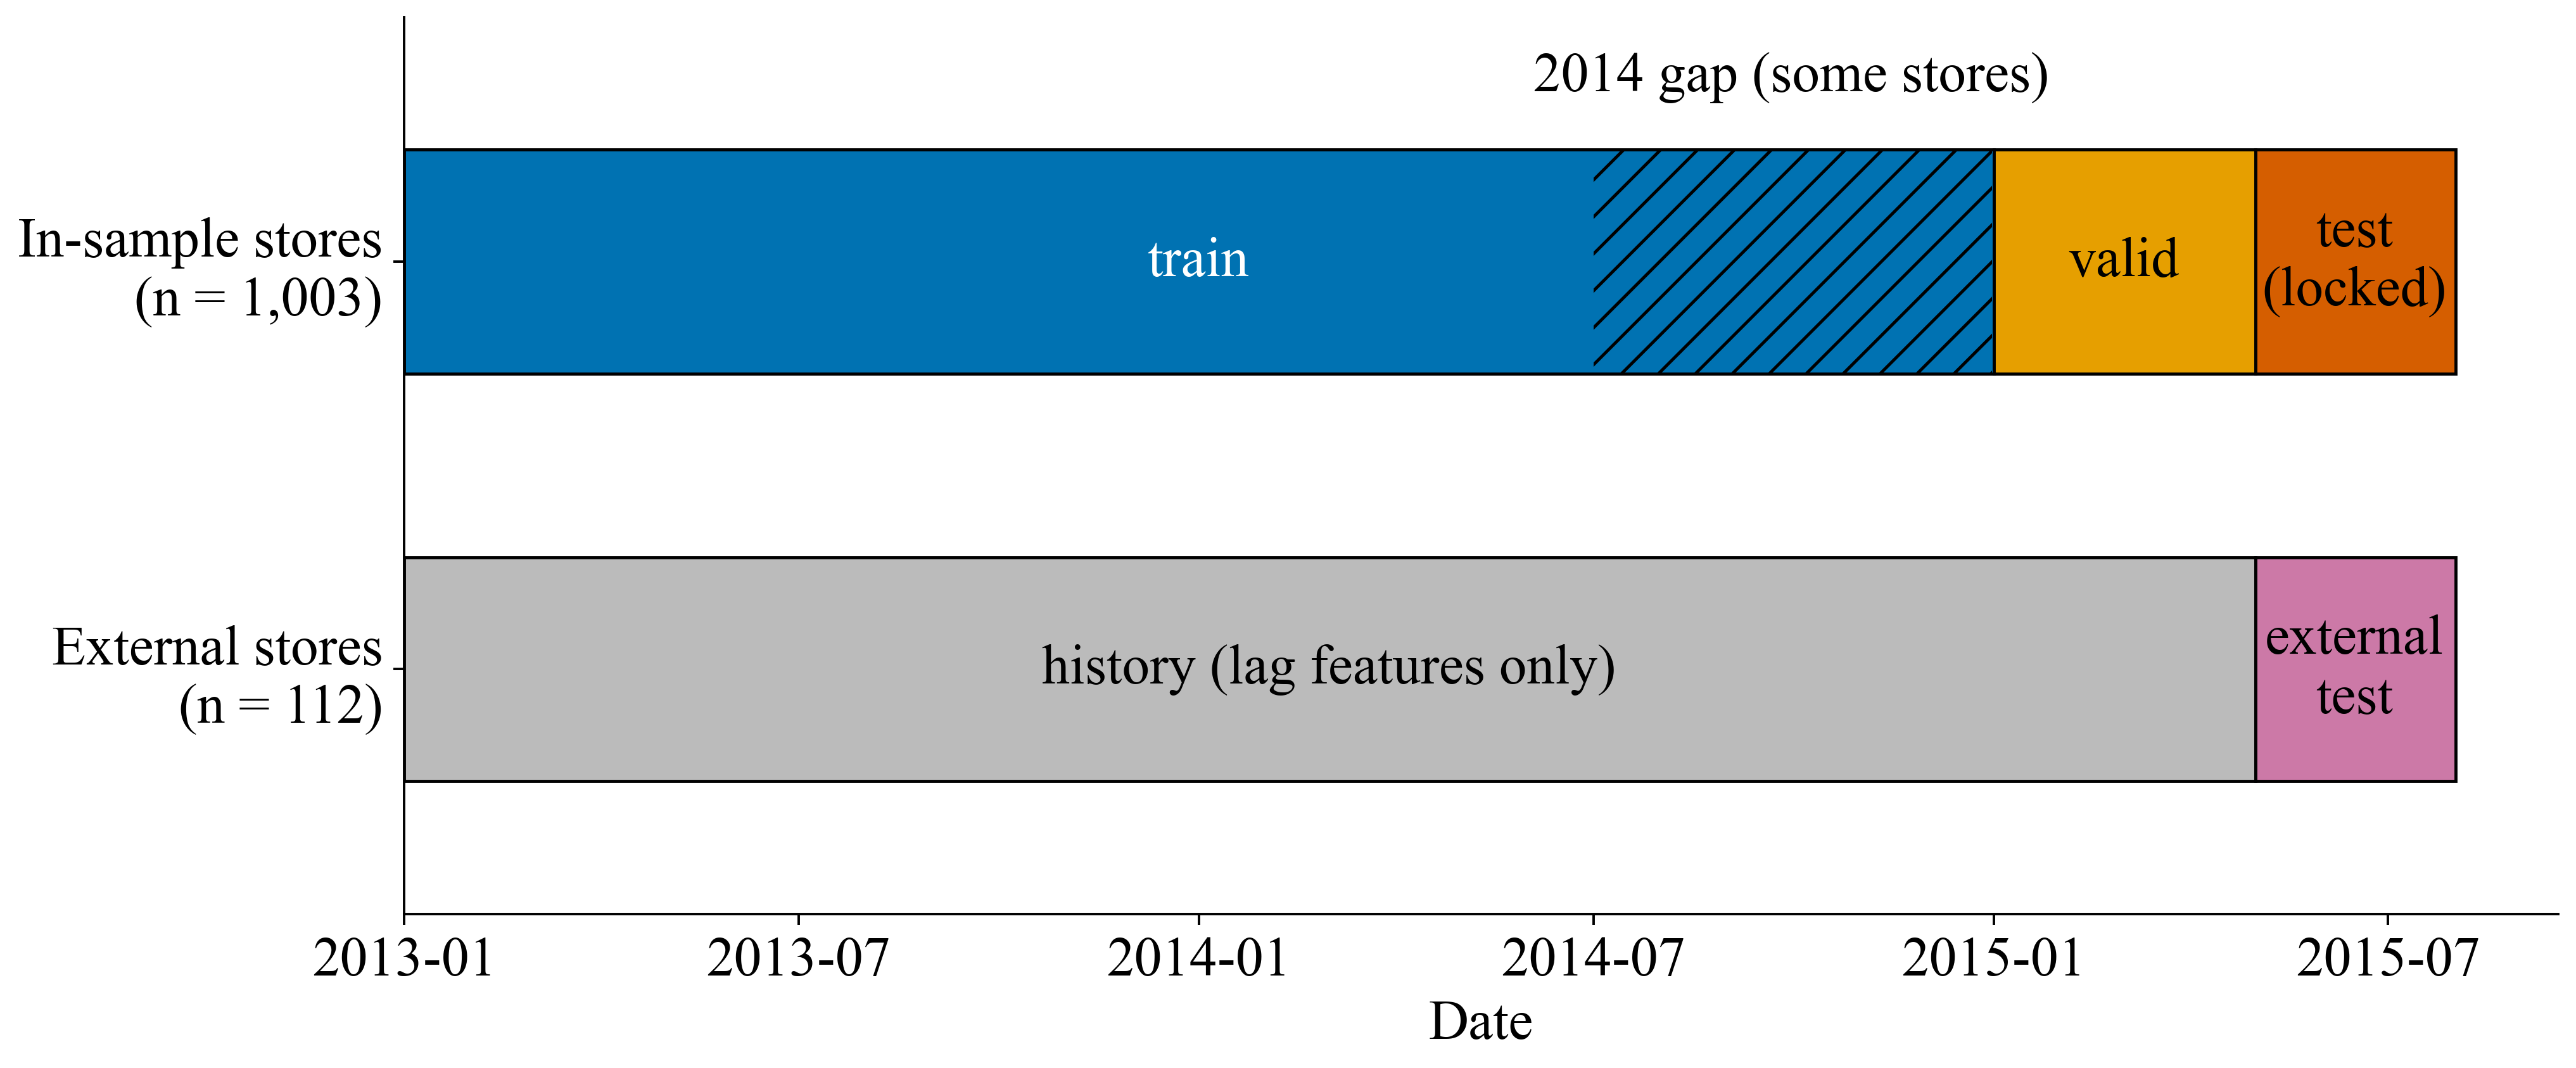

In [7]:
fig, ax = plt.subplots(figsize=(12, 5.2))
segments = [
    (
        "In-sample stores\n(n = 1,003)",
        "2013-01-01",
        BOUNDS["train_end"],
        "train",
        PALETTE[0],
    ),
    (
        "In-sample stores\n(n = 1,003)",
        "2015-01-01",
        BOUNDS["valid_end"],
        "valid",
        PALETTE[1],
    ),
    (
        "In-sample stores\n(n = 1,003)",
        "2015-05-01",
        BOUNDS["test_end"],
        "test\n(locked)",
        PALETTE[3],
    ),
    (
        "External stores\n(n = 112)",
        "2013-01-01",
        BOUNDS["valid_end"],
        "history (lag features only)",
        "#BBBBBB",
    ),
    (
        "External stores\n(n = 112)",
        "2015-05-01",
        BOUNDS["test_end"],
        "external\ntest",
        PALETTE[4],
    ),
]
ylab = {"In-sample stores\n(n = 1,003)": 1, "External stores\n(n = 112)": 0}
seen = set()
for row, a, b, lab, col in segments:
    a, b = pd.Timestamp(a), pd.Timestamp(b)
    ax.barh(
        ylab[row],
        (b - a).days + 1,
        left=a,
        height=0.55,
        color=col,
        edgecolor="black",
        label=lab if lab not in seen else None,
    )
    ax.text(
        a + (b - a) / 2,
        ylab[row],
        lab,
        ha="center",
        va="center",
        fontsize=18,
        color="white" if col == PALETTE[0] else "black",
    )
    seen.add(lab)
ax.set_yticks([0, 1])
ax.set_yticklabels(list(ylab)[::-1])
ax.set_xlabel("Date")
ax.set_ylim(-0.6, 1.6)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.axvspan(
    pd.Timestamp("2014-07-01"),
    pd.Timestamp("2014-12-31"),
    ymin=(0.725 + 0.6) / 2.2,
    ymax=(1.275 + 0.6) / 2.2,
    facecolor="none",
    hatch="//",
    edgecolor="black",
    lw=0,
)
ax.text(
    pd.Timestamp("2014-09-30"), 1.42, "2014 gap (some stores)", ha="center", fontsize=18
)
fig.tight_layout()
save_fig(fig, "fig1_1_study_design_timeline")
show_fig("fig1_1_study_design_timeline")
pd.DataFrame(
    [
        {"partition": k, "start": str(v[0]), "end": str(v[1])}
        for k, v in {
            "train": ("2013-01-01", BOUNDS["train_end"]),
            "valid": ("2015-01-01", BOUNDS["valid_end"]),
            "test_locked": ("2015-05-01", BOUNDS["test_end"]),
        }.items()
    ]
).to_csv(TABLES / "fig1_1_partition_timeline_numeric.csv", index=False)


## 3. Schema and availability of each column at forecast time

In [8]:
schema_meta = {
    "Store": ("identifier", "store id (1–1,115)", "static"),
    "DayOfWeek": ("calendar", "1 = Monday .. 7 = Sunday", "deterministic"),
    "Date": ("calendar", "day", "deterministic"),
    "Sales": ("target", "EUR per day", "observed on day t (target)"),
    "Customers": (
        "contemporaneous",
        "customers per day",
        "observed on day t: not usable as covariate",
    ),
    "Open": (
        "contemporaneous",
        "1 = open",
        "observed on day t: defines the row filter only",
    ),
    "Promo": ("schedule", "1 = store-level promotion that day", "known in advance"),
    "StateHoliday": (
        "schedule",
        "0 none, a public, b Easter, c Christmas",
        "known in advance",
    ),
    "SchoolHoliday": ("schedule", "1 = school holiday", "known in advance"),
    "StoreType": ("store attribute", "a, b, c, d", "static"),
    "Assortment": ("store attribute", "a basic, b extra, c extended", "static"),
    "CompetitionDistance": (
        "store attribute",
        "metres to nearest competitor",
        "static",
    ),
    "CompetitionOpenSinceMonth": ("store attribute", "month", "static"),
    "CompetitionOpenSinceYear": ("store attribute", "year", "static"),
    "Promo2": ("schedule", "1 = participates in the continuing promotion", "static"),
    "Promo2SinceWeek": ("schedule", "ISO week", "static"),
    "Promo2SinceYear": ("schedule", "year", "static"),
    "PromoInterval": ("schedule", "months in which Promo2 restarts", "static"),
}
schema = []
for c, (role, unit, avail) in schema_meta.items():
    s = dev[c]
    num = pd.api.types.is_numeric_dtype(s)
    schema.append(
        {
            "column": c,
            "role": role,
            "unit / coding": unit,
            "known at forecast time": avail,
            "dtype": str(s.dtype),
            "unique values": s.nunique(dropna=True),
            "missing %": 100 * s.isna().mean(),
            "min": s.min() if num else "",
            "max": s.max() if num else "",
        }
    )
schema = pd.DataFrame(schema).set_index("column")
save_table(
    schema,
    "tab1_5_schema_and_availability",
    "Schema of the Rossmann store-day table (1,003 in-sample stores, labels through April 24, 2015): role, unit, availability at forecast time, missingness and range.",
    float_format="%.2f",
)


,role,unit / coding,known at forecast time,dtype,unique values,missing %,min,max
column,,,,,,,,
Store,identifier,"store id (1–1,115)",static,int64,1003,0.0000,1,1115
DayOfWeek,calendar,1 = Monday .. 7 = Sunday,deterministic,int64,7,0.0000,1,7
Date,calendar,day,deterministic,datetime64[ns],844,0.0000,,
Sales,target,EUR per day,observed on day t (target),int64,21098,0.0000,0,38722
Customers,contemporaneous,customers per day,observed on day t: not usable as covariate,int64,4029,0.0000,0,7388
Open,contemporaneous,1 = open,observed on day t: defines the row filter only,int64,2,0.0000,0,1
Promo,schedule,1 = store-level promotion that day,known in advance,int64,2,0.0000,0,1
StateHoliday,schedule,"0 none, a public, b Easter, c Christmas",known in advance,object,4,0.0000,,
SchoolHoliday,schedule,1 = school holiday,known in advance,int64,2,0.0000,0,1


## 4. Data quality of the development data

In [9]:
num_cols = dev.select_dtypes("number").columns
OPERATIONAL = [
    "Store",
    "Date",
    "DayOfWeek",
    "Sales",
    "Customers",
    "Open",
    "Promo",
    "StateHoliday",
    "SchoolHoliday",
    "StoreType",
    "Assortment",
]
dup_pairs = int(dev.duplicated(["Store", "Date"]).sum())
dow_mismatch = int((dev["DayOfWeek"] != dev["Date"].dt.dayofweek + 1).sum())
p2 = dev.drop_duplicates("Store")
quality = pd.DataFrame(
    [
        (
            "completeness",
            "NaN cells (all columns)",
            int(dev.isna().sum().sum()),
            100 * dev.isna().sum().sum() / dev.size,
        ),
        (
            "completeness",
            "NaN cells in operational columns (identifiers, target, Customers, Open, schedule, store type, assortment)",
            int(dev[OPERATIONAL].isna().sum().sum()),
            100 * dev[OPERATIONAL].isna().sum().sum() / dev[OPERATIONAL].size,
        ),
        (
            "completeness",
            "±Inf cells (numeric columns)",
            int(np.isinf(dev[num_cols].to_numpy(dtype=float)).sum()),
            0.0,
        ),
        (
            "uniqueness",
            "duplicated (Store, Date) pairs",
            dup_pairs,
            100 * dup_pairs / len(dev),
        ),
        (
            "uniqueness",
            "fully duplicated rows",
            int(dev.duplicated().sum()),
            100 * dev.duplicated().sum() / len(dev),
        ),
        (
            "consistency",
            "DayOfWeek inconsistent with Date",
            dow_mismatch,
            100 * dow_mismatch / len(dev),
        ),
        (
            "consistency",
            "closed (Open = 0) with Sales > 0",
            int(((dev["Open"] == 0) & (dev["Sales"] > 0)).sum()),
            100 * ((dev["Open"] == 0) & (dev["Sales"] > 0)).mean(),
        ),
        (
            "consistency",
            "open (Open = 1) with Sales = 0",
            int(((dev["Open"] == 1) & (dev["Sales"] == 0)).sum()),
            100 * ((dev["Open"] == 1) & (dev["Sales"] == 0)).mean(),
        ),
        (
            "consistency",
            "Sales > 0 with Customers = 0",
            int(((dev["Sales"] > 0) & (dev["Customers"] == 0)).sum()),
            100 * ((dev["Sales"] > 0) & (dev["Customers"] == 0)).mean(),
        ),
        (
            "consistency",
            "Customers > 0 with Sales = 0",
            int(((dev["Customers"] > 0) & (dev["Sales"] == 0)).sum()),
            100 * ((dev["Customers"] > 0) & (dev["Sales"] == 0)).mean(),
        ),
        (
            "consistency",
            "Promo2 = 1 with missing Promo2 start",
            int(((p2["Promo2"] == 1) & p2["Promo2SinceYear"].isna()).sum()),
            100 * ((p2["Promo2"] == 1) & p2["Promo2SinceYear"].isna()).mean(),
        ),
        (
            "consistency",
            "Promo2 = 0 with a PromoInterval",
            int(((p2["Promo2"] == 0) & p2["PromoInterval"].notna()).sum()),
            100 * ((p2["Promo2"] == 0) & p2["PromoInterval"].notna()).mean(),
        ),
        (
            "plausibility",
            "negative Sales or Customers",
            int(((dev["Sales"] < 0) | (dev["Customers"] < 0)).sum()),
            100 * ((dev["Sales"] < 0) | (dev["Customers"] < 0)).mean(),
        ),
        (
            "plausibility",
            "stores with CompetitionDistance missing",
            int(p2["CompetitionDistance"].isna().sum()),
            100 * p2["CompetitionDistance"].isna().mean(),
        ),
        (
            "plausibility",
            "stores with competition opening date missing",
            int(p2["CompetitionOpenSinceYear"].isna().sum()),
            100 * p2["CompetitionOpenSinceYear"].isna().mean(),
        ),
        (
            "plausibility",
            "stores with competition opening year < 1950",
            int((p2["CompetitionOpenSinceYear"] < 1950).sum()),
            100 * (p2["CompetitionOpenSinceYear"] < 1950).mean(),
        ),
        (
            "plausibility",
            "stores with CompetitionDistance > 50 km",
            int((p2["CompetitionDistance"] > 50_000).sum()),
            100 * (p2["CompetitionDistance"] > 50_000).mean(),
        ),
        (
            "coverage",
            f"all-store identifier coverage: fewer than {days_per_store.max()} recorded days",
            gap_stores,
            100 * gap_stores / len(days_per_store),
        ),
        (
            "coverage",
            "closed store-days (Open = 0)",
            int((dev["Open"] == 0).sum()),
            100 * (dev["Open"] == 0).mean(),
        ),
    ],
    columns=["family", "check", "count", "share %"],
).set_index(["family", "check"])
quality["share %"] = quality["share %"].astype(float)
save_table(
    quality,
    "tab1_6_data_quality_checks",
    "Data-quality checks on 1,003 in-sample stores through April 24, 2015; shares use store-days or stores as appropriate. The identifier-only full-span recording-gap check covers all 1,115 stores.",
    float_format="%.3f",
)


count share %
family       check                                                                                                                     
completeness NaN cells (all columns)                                                                                    1759577 10.2615
             NaN cells in operational columns (identifiers, target, Customers, Open, schedule, store type, assortment)        0  0.0000
             ±Inf cells (numeric columns)                                                                                     0  0.0000
uniqueness   duplicated (Store, Date) pairs                                                                                   0  0.0000
             fully duplicated rows                                                                                            0  0.0000
consistency  DayOfWeek inconsistent with Date                                                                                 0  0.0000
             closed (Open = 0) with Sales > 0                                                                                 0  0.0000
             open (Open = 1) with Sales = 0                                                                                  50  0.0061
             Sales > 0 with Customers = 0                                                                                     0  0.0000
             Customers > 0 with Sales = 0                                                                                     2  0.0002
             Promo2 = 1 with missing Promo2 start                                                                             0  0.0000
             Promo2 = 0 with a PromoInterval                                                                                  0  0.0000
plausibility negative Sales or Customers                                                                                      0  0.0000
             stores with CompetitionDistance missing                                                                          2  0.1994
             stores with competition opening date missing                                                                   320 31.9043
             stores with competition opening year < 1950                                                                      1  0.0997
             stores with CompetitionDistance > 50 km                                                                          1  0.0997
coverage     all-store identifier coverage: fewer than 942 recorded days                                                    181 16.2332
             closed store-days (Open = 0)                                                                                138333 16.9414

In [10]:
# outliers and rare categories on retained in-sample development rows
z = dev_ret.groupby("Store")["log_sales"].transform(lambda s: (s - s.mean()) / s.std())
ratio_med = dev_ret["Sales"] / dev_ret.groupby("Store")["Sales"].transform("median")
rare = pd.DataFrame(
    [
        (
            "outliers",
            "store-days with |z| > 4 (within-store log sales)",
            int((z.abs() > 4).sum()),
            100 * (z.abs() > 4).mean(),
        ),
        (
            "outliers",
            "store-days with sales > 3 x store median",
            int((ratio_med > 3).sum()),
            100 * (ratio_med > 3).mean(),
        ),
        (
            "outliers",
            "store-days with sales < store median / 3",
            int((ratio_med < 1 / 3).sum()),
            100 * (ratio_med < 1 / 3).mean(),
        ),
        (
            "rare category",
            "StateHoliday = a (public holiday) store-days",
            int((dev_ret["StateHoliday"] == "a").sum()),
            100 * (dev_ret["StateHoliday"] == "a").mean(),
        ),
        (
            "rare category",
            "StateHoliday = b (Easter) store-days",
            int((dev_ret["StateHoliday"] == "b").sum()),
            100 * (dev_ret["StateHoliday"] == "b").mean(),
        ),
        (
            "rare category",
            "StateHoliday = c (Christmas) store-days",
            int((dev_ret["StateHoliday"] == "c").sum()),
            100 * (dev_ret["StateHoliday"] == "c").mean(),
        ),
        (
            "rare category",
            "Sunday store-days",
            int((dev_ret["DayOfWeek"] == 7).sum()),
            100 * (dev_ret["DayOfWeek"] == 7).mean(),
        ),
        (
            "rare category",
            "StoreType = b stores",
            int((dev_ret.drop_duplicates("Store")["StoreType"] == "b").sum()),
            100 * (dev_ret.drop_duplicates("Store")["StoreType"] == "b").mean(),
        ),
        (
            "rare category",
            "Assortment = b stores",
            int((dev_ret.drop_duplicates("Store")["Assortment"] == "b").sum()),
            100 * (dev_ret.drop_duplicates("Store")["Assortment"] == "b").mean(),
        ),
    ],
    columns=["family", "check", "count", "share %"],
).set_index(["family", "check"])
save_table(
    rare,
    "tab1_7_outliers_and_rare_categories",
    "Outliers (within-store) and rare categories on retained in-sample development store-days; store-level shares for store attributes.",
    float_format="%.3f",
)


count share %
family        check                                                         
outliers      store-days with |z| > 4 (within-store log sales)   435  0.0641
              store-days with sales > 3 x store median           141  0.0208
              store-days with sales < store median / 3          1240  0.1828
rare category StateHoliday = a (public holiday) store-days       464  0.0684
              StateHoliday = b (Easter) store-days               130  0.0192
              StateHoliday = c (Christmas) store-days             67  0.0099
              Sunday store-days                                 2801  0.4130
              StoreType = b stores                                16  1.5952
              Assortment = b stores                                8  0.7976

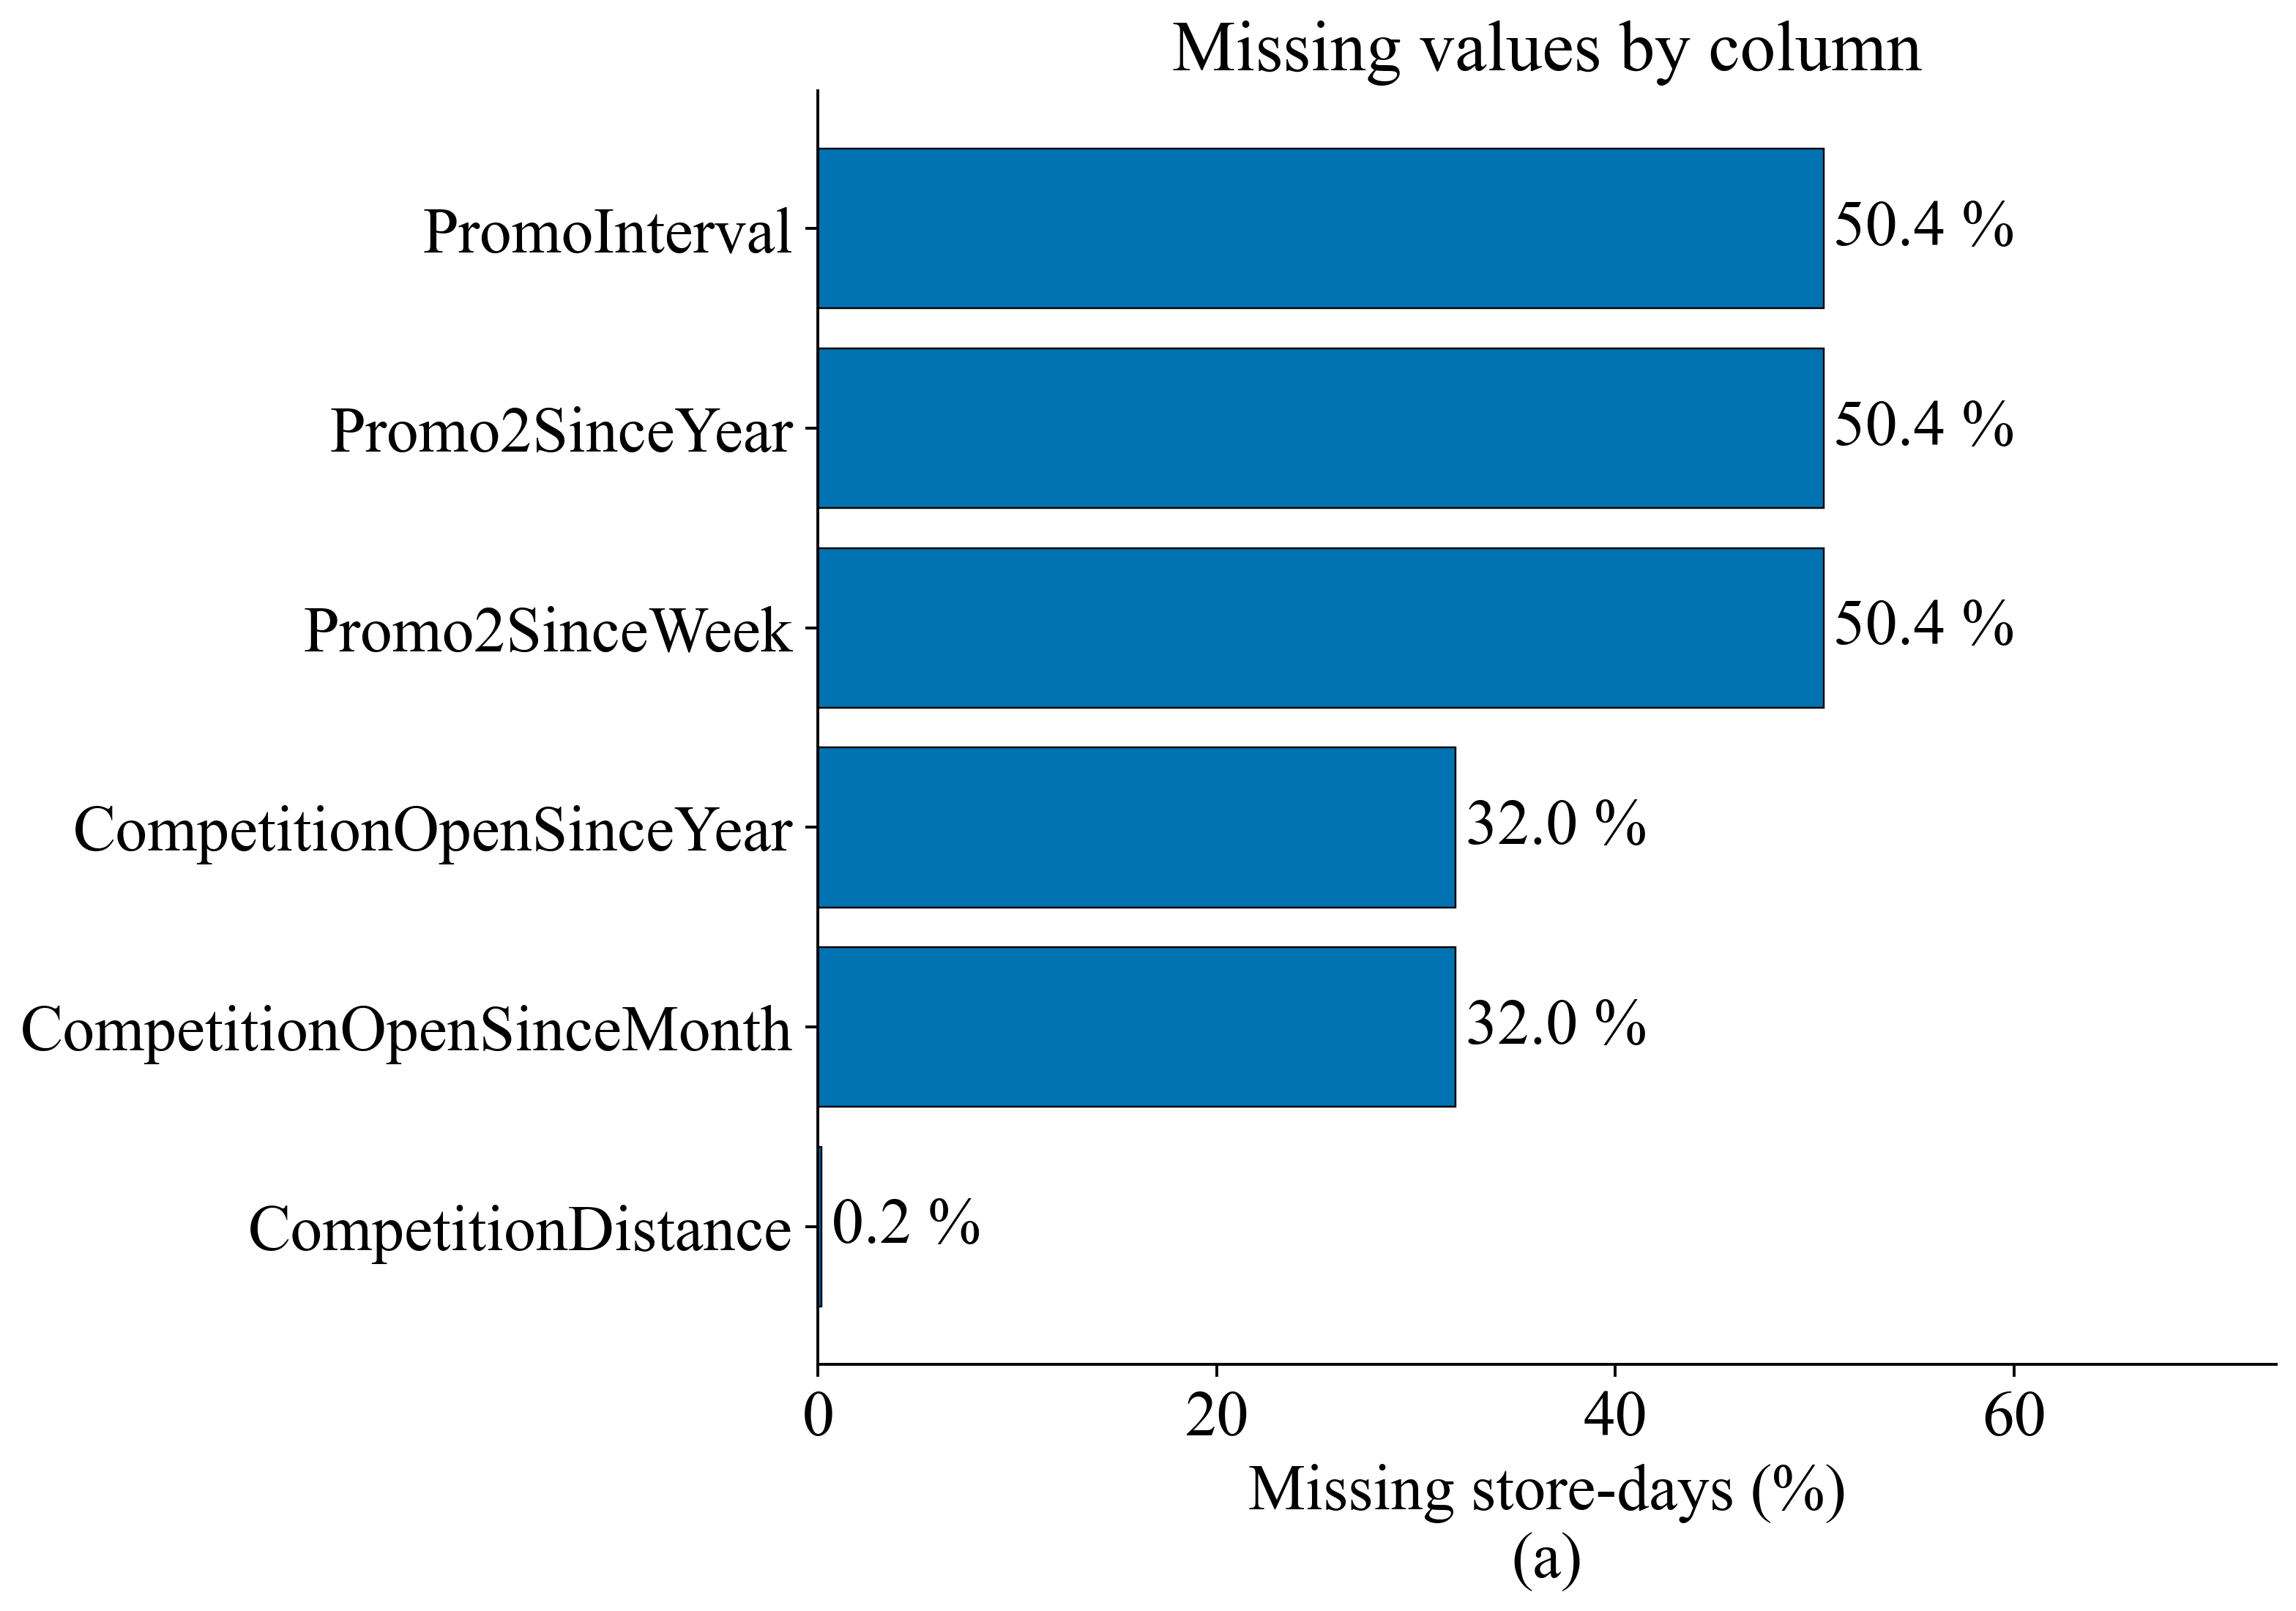

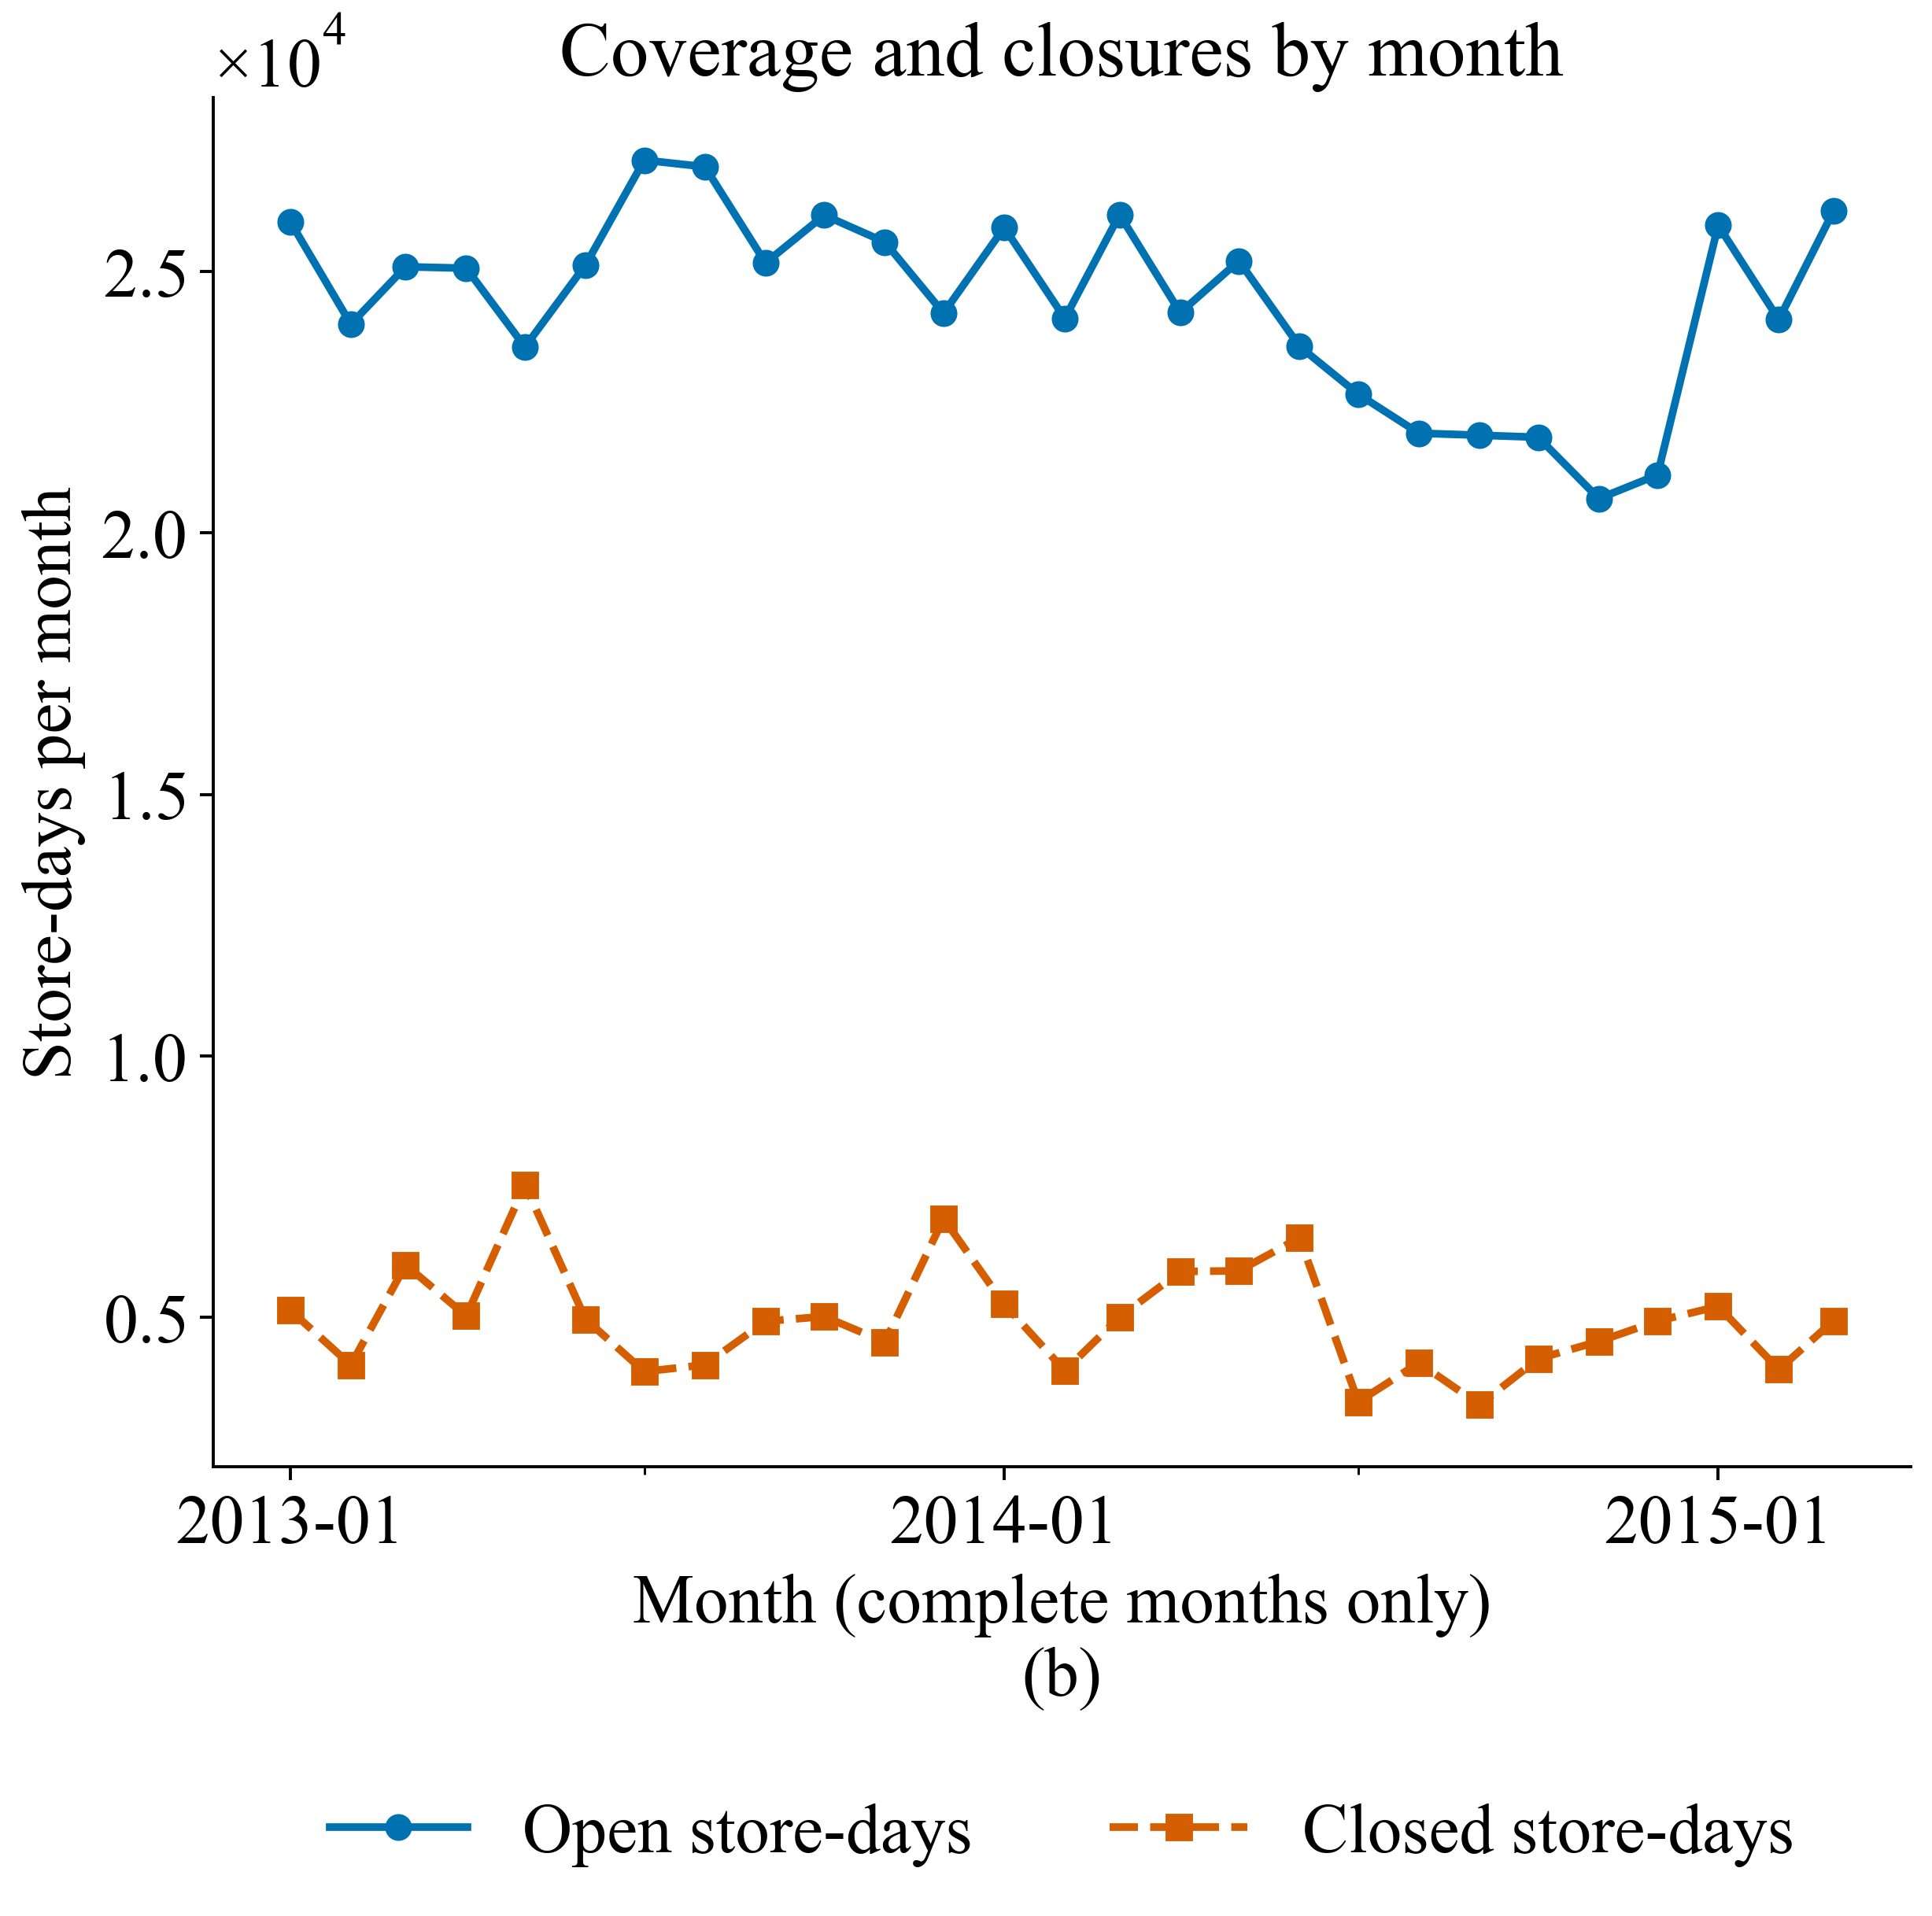

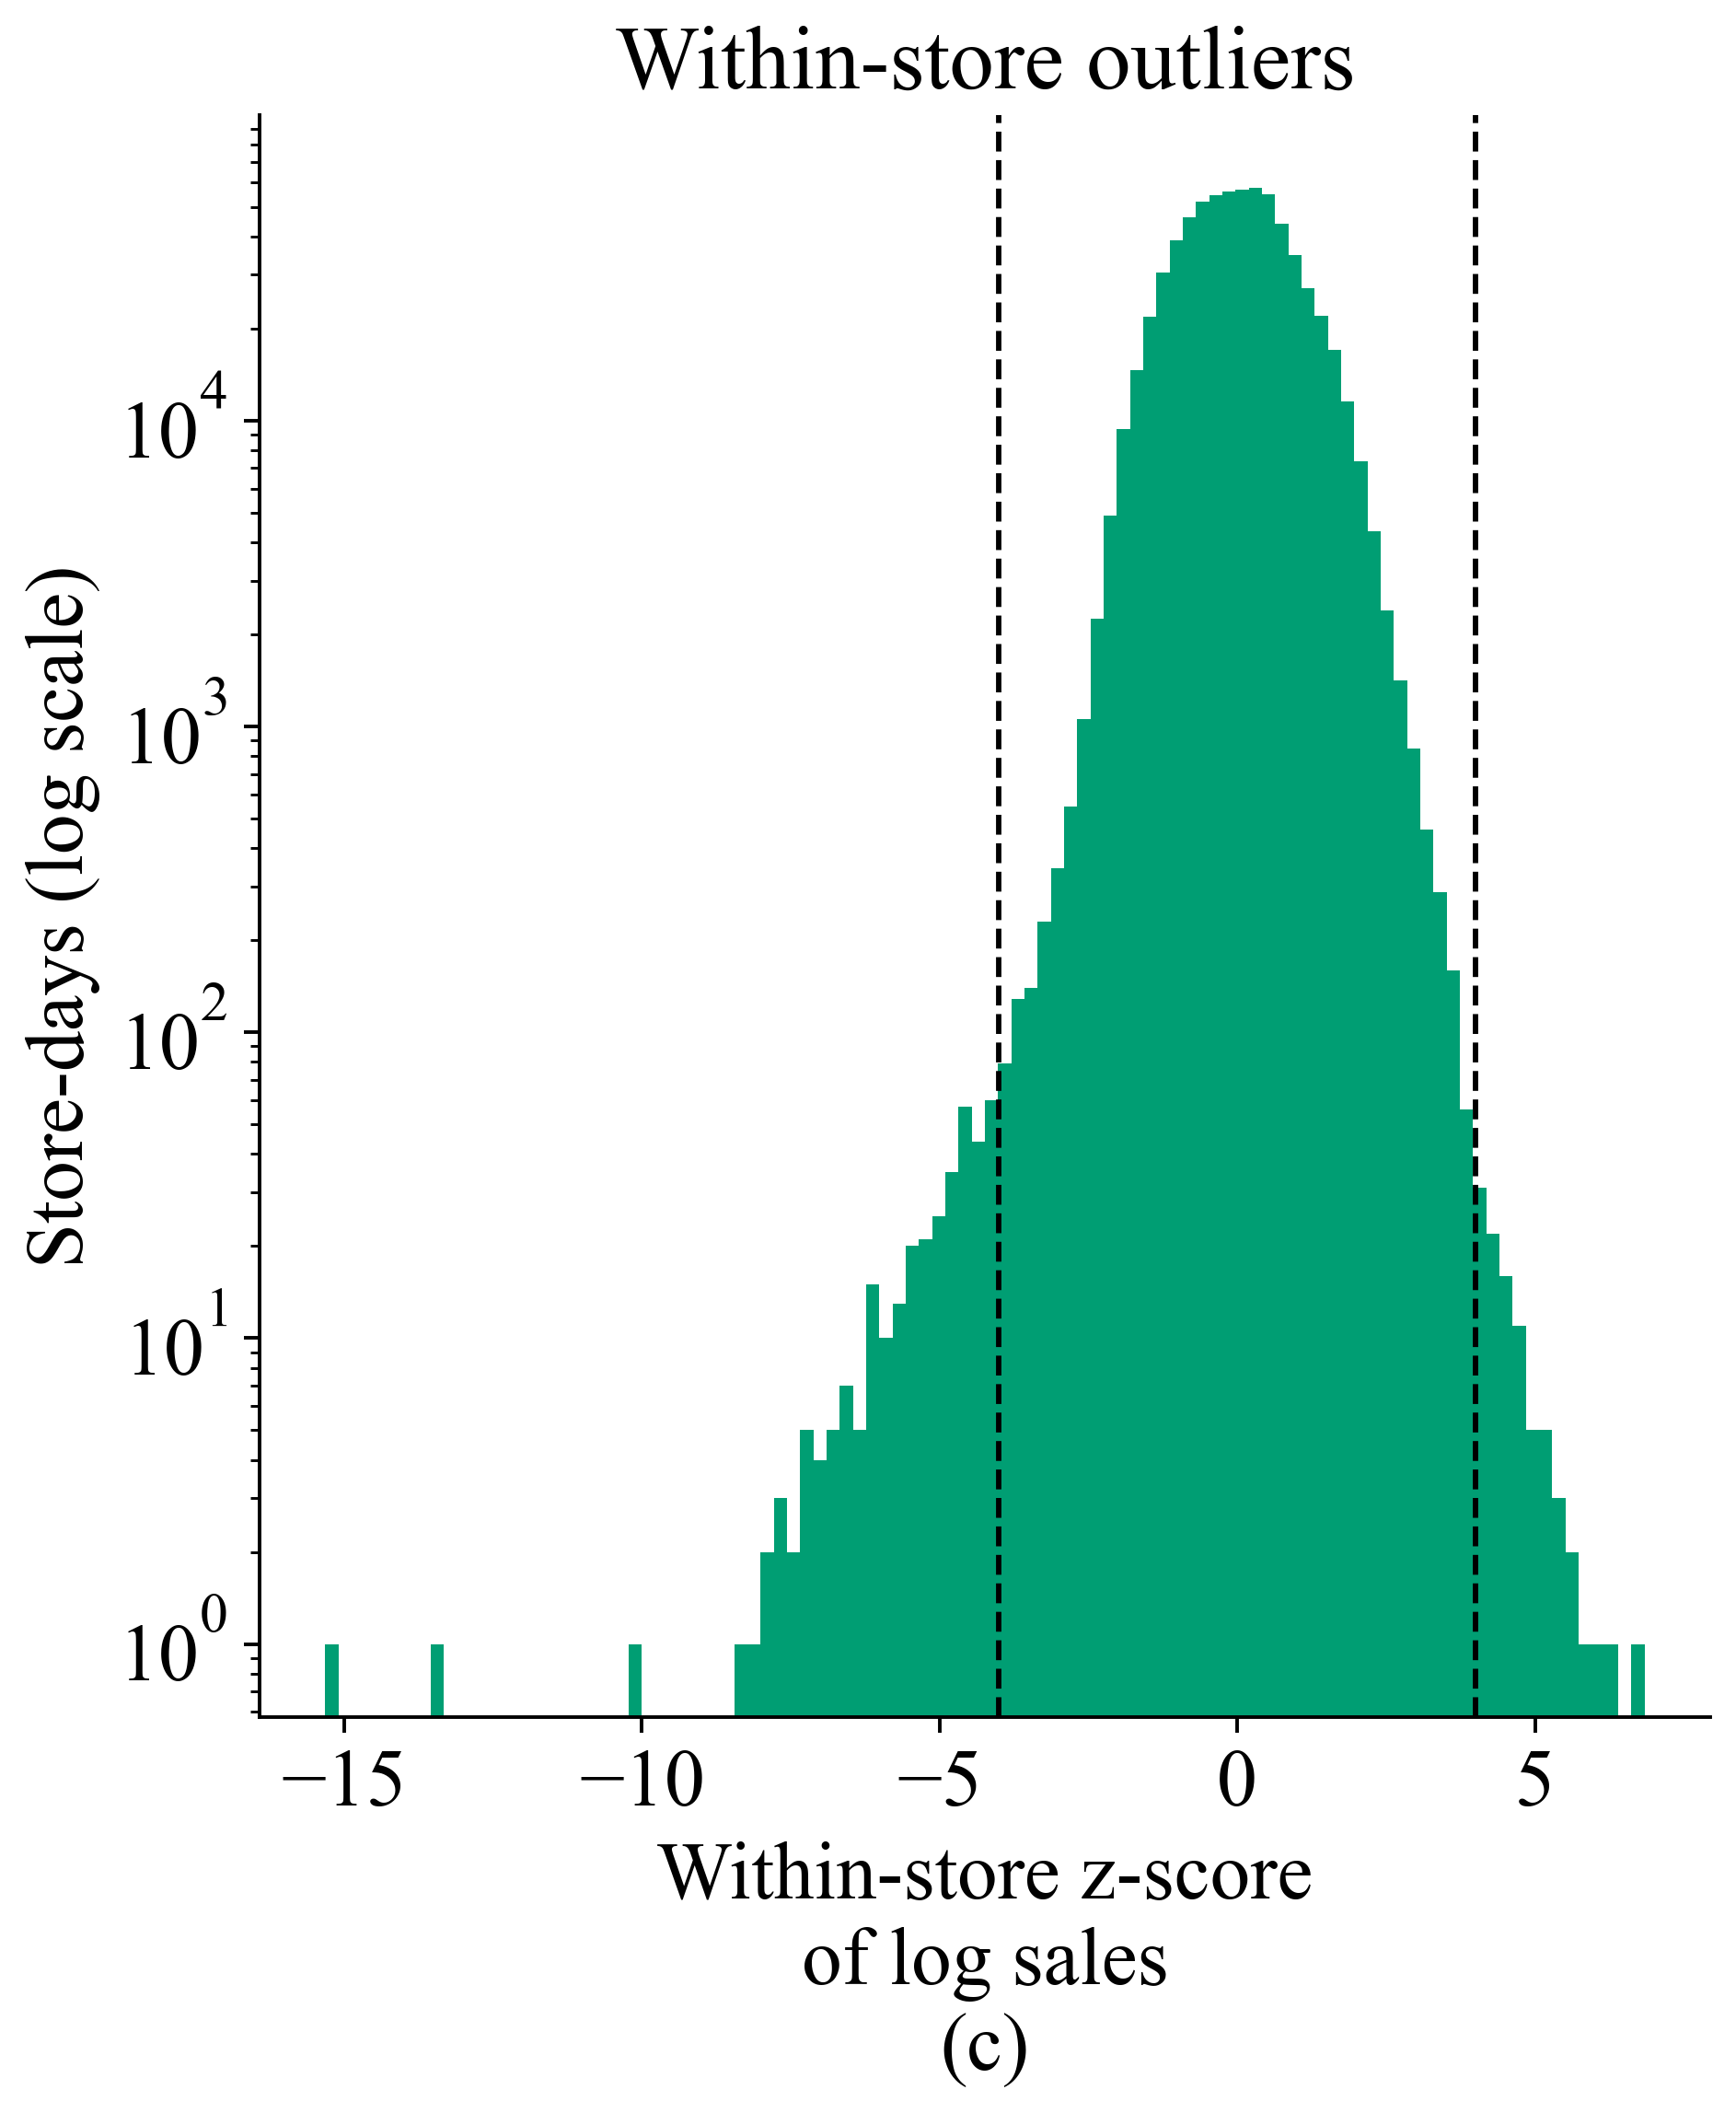

In [11]:
miss = (100 * dev.isna().mean()).loc[lambda s: s > 0].sort_values()
monthly = (
    dev.assign(month=dev["Date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month")
    .agg(open=("Open", "sum"), closed=("Open", lambda s: (s == 0).sum()))
)
monthly = monthly[
    (monthly.index + pd.offsets.MonthEnd(0))
    <= pd.Timestamp(design["selection_label_cutoff"])
]
monthly.to_csv(TABLES / "monthly_coverage_numeric.csv")
miss.to_csv(TABLES / "missingness_numeric.csv", header=["missing_pct"])
fig, axes = plt.subplots(
    1, 3, figsize=(22, 7.5), gridspec_kw={"width_ratios": [1.2, 1.3, 0.95]}
)
axes[0].barh(miss.index, miss.values, color=PALETTE[0], edgecolor="black", lw=0.5)
for i, v in enumerate(miss.values):
    axes[0].text(v + 0.5, i, f"{v:.1f} %", va="center", fontsize=18)
axes[0].set_xlim(0, miss.max() * 1.45)
axes[0].set_xlabel("Missing store-days (%)")
axes[0].set_title("Missing values by column")
axes[1].plot(
    monthly.index,
    monthly["open"],
    color=PALETTE[0],
    marker="o",
    lw=2,
    label="Open store-days",
)
axes[1].plot(
    monthly.index,
    monthly["closed"],
    color=PALETTE[3],
    marker="s",
    ls="--",
    lw=2,
    label="Closed store-days",
)
axes[1].set_ylabel("Store-days per month")
axes[1].set_xlabel("Month (complete months only)")
axes[1].set_title("Coverage and closures by month")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)  # legend directly under the panel label, no empty band
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1,)))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=(7,)))
axes[2].hist(z.dropna(), bins=100, color=PALETTE[2], edgecolor="none")
axes[2].axvline(-4, color="black", ls="--", lw=1.2)
axes[2].axvline(4, color="black", ls="--", lw=1.2)
axes[2].set_yscale("log")
axes[2].set_xlabel("Within-store z-score\nof log sales")
axes[2].set_ylabel("Store-days (log scale)")
axes[2].set_title("Within-store outliers")
label_panels(axes)
fig.tight_layout()
save_fig(fig, "fig1_2_data_quality")
show_fig("fig1_2_data_quality")
hist_counts, hist_edges = np.histogram(z.dropna(), bins=100)
pd.DataFrame(
    {
        "bin_left": hist_edges[:-1],
        "bin_right": hist_edges[1:],
        "store_days": hist_counts,
    }
).to_csv(TABLES / "fig1_2_outlier_histogram_numeric.csv", index=False)


## 5. Target distribution, heterogeneity and group differences (development data)

In [12]:
desc = (
    dev_ret[["Sales", "Customers"]]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
)
desc["skew"] = dev_ret[["Sales", "Customers"]].skew()
desc["log skew"] = np.log(
    dev_ret[["Sales", "Customers"]].where(dev_ret[["Sales", "Customers"]] > 0)
).skew()
desc["log excess kurtosis"] = np.log(
    dev_ret[["Sales", "Customers"]].where(dev_ret[["Sales", "Customers"]] > 0)
).kurt()
save_table(
    desc,
    "tab1_8_target_summary",
    "Summary statistics of daily Sales and Customers on retained in-sample development store-days.",
    float_format="%.2f",
)


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,log skew,log excess kurtosis
Sales,"678,156.0000","6,908.0543","3,115.9606",124.0000,"2,174.0000","3,137.0000","4,810.0000","6,310.0000","8,300.0000","12,646.0000","17,899.0000","38,722.0000",1.6333,-0.0860,0.6222
Customers,"678,156.0000",765.1868,407.6408,13.0000,249.0000,346.0000,518.0000,676.0000,897.0000,"1,449.0000","2,464.0000","7,388.0000",2.8008,0.3209,1.0367


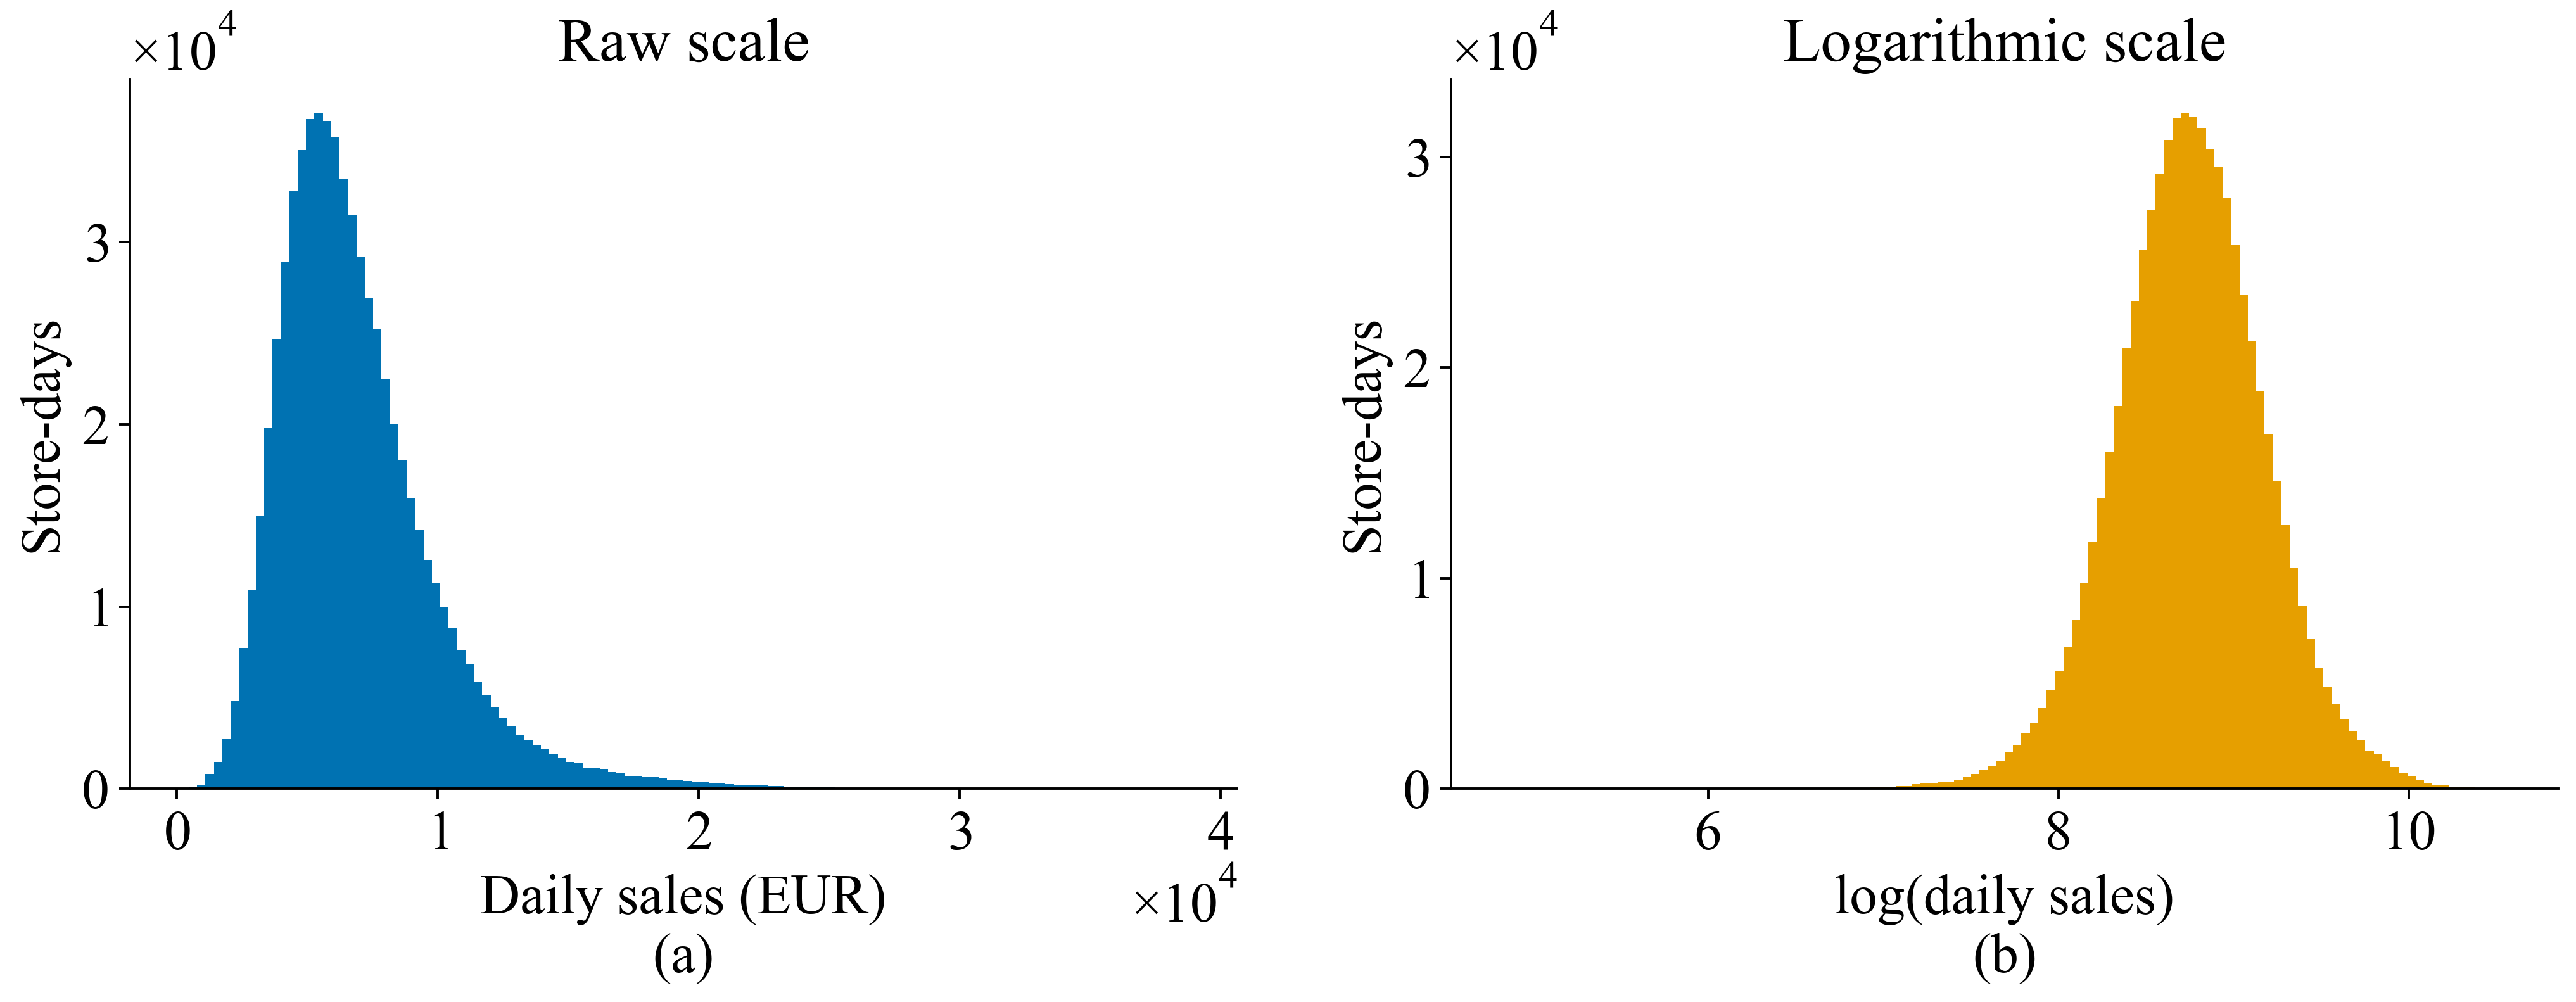

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.9))
axes[0].hist(dev_ret["Sales"], bins=120, color=PALETTE[0], edgecolor="none")
axes[0].set_xlabel("Daily sales (EUR)")
axes[0].set_ylabel("Store-days")
axes[0].set_title("Raw scale")
axes[0].ticklabel_format(axis="both", style="sci", scilimits=(0, 0), useMathText=True)
axes[1].hist(dev_ret["log_sales"], bins=120, color=PALETTE[1], edgecolor="none")
axes[1].set_xlabel("log(daily sales)")
axes[1].set_ylabel("Store-days")
axes[1].set_title("Logarithmic scale")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
label_panels(axes)
fig.tight_layout()
save_fig(fig, "fig1_3_sales_distribution")
show_fig("fig1_3_sales_distribution", width=1300)
for source_name, values in [("sales", dev_ret.Sales), ("log_sales", dev_ret.log_sales)]:
    hist_counts, hist_edges = np.histogram(values, bins=120)
    pd.DataFrame(
        {
            "bin_left": hist_edges[:-1],
            "bin_right": hist_edges[1:],
            "store_days": hist_counts,
        }
    ).to_csv(TABLES / ("fig1_3_" + source_name + "_numeric.csv"), index=False)


In [14]:
het = dev_ret.groupby(["StoreType", "Assortment"]).agg(
    stores=("Store", "nunique"),
    store_days=("Sales", "size"),
    mean_sales=("Sales", "mean"),
    median_sales=("Sales", "median"),
    cv_sales=("Sales", lambda s: s.std() / s.mean()),
)
save_table(
    het,
    "tab1_9_store_heterogeneity",
    "Store heterogeneity by type and assortment on retained in-sample development store-days.",
    float_format="%.2f",
)


stores store_days  mean_sales median_sales cv_sales
StoreType Assortment                                                    
a         a             338     226474  6,486.5148   5,883.0000   0.4755
          c             199     137560  7,466.0225   6,753.0000   0.4674
b         a               7       5723 11,082.9394   9,534.0000   0.5063
          b               8       6495  8,869.5433   8,582.0000   0.4314
          c               1        844 17,965.5569  17,965.5000   0.1640
c         a              72      48853  6,884.1029   6,491.0000   0.3722
          c              63      43082  7,029.8076   6,350.0000   0.4629
d         a             116      75848  6,378.8075   6,002.0000   0.3774
          c             199     133277  6,974.1978   6,500.0000   0.3771

In [15]:
store_lvl = dev_ret.groupby("Store").agg(
    mean_log=("log_sales", "mean"),
    StoreType=("StoreType", "first"),
    Assortment=("Assortment", "first"),
)


def kruskal_row(frame, col, value, unit):
    groups = [g[value].to_numpy() for _, g in frame.groupby(col)]
    H, p = stats.kruskal(*groups)
    k, n = len(groups), sum(map(len, groups))
    med = frame.groupby(col)[value].median()
    return {
        "factor": col,
        "unit of analysis": unit,
        "levels": k,
        "n": n,
        "test": "Kruskal–Wallis",
        "statistic": H,
        "p-value": p,
        "effect size": (H - k + 1) / (n - k),
        "effect measure": "epsilon squared",
        "contrast (% of level with smallest median)": 100
        * (np.exp(med.max() - med.min()) - 1),
    }


def paired_row(frame, col, name):
    """Per-store mean log sales with factor = 1 minus with factor = 0; Wilcoxon signed-rank across stores, rank-biserial effect size."""
    m = frame.groupby(["Store", col])["log_sales"].mean().unstack(col)
    m = m.dropna()
    d = (m[1] - m[0]).to_numpy()
    d = d[d != 0]
    r = stats.rankdata(np.abs(d))
    rp, rn = r[d > 0].sum(), r[d < 0].sum()
    W, p = stats.wilcoxon(d)
    return {
        "factor": name,
        "unit of analysis": "store (paired contrast)",
        "levels": 2,
        "n": len(d),
        "test": "Wilcoxon signed-rank",
        "statistic": W,
        "p-value": p,
        "effect size": (rp - rn) / (rp + rn),
        "effect measure": "rank-biserial r",
        "contrast (% of level with smallest median)": 100 * (np.exp(np.median(d)) - 1),
    }


def repeated_row(frame, factor):
    panel = frame.pivot(index="Store", columns=factor, values="dev_log").dropna()
    result = stats.friedmanchisquare(*(panel[c].to_numpy() for c in panel.columns))
    n, k = panel.shape
    return {
        "factor": factor,
        "unit of analysis": "store (complete repeated measures)",
        "levels": k,
        "n": n,
        "test": "Friedman",
        "statistic": result.statistic,
        "p-value": result.pvalue,
        "effect size": result.statistic / (n * (k - 1)),
        "effect measure": "Kendall W",
        "contrast (% of level with smallest median)": 100
        * np.expm1(panel.median().max() - panel.median().min()),
    }


sm = dev_ret.assign(
    month=dev_ret["Date"].dt.month,
    year=dev_ret["Date"].dt.year,
    dow=dev_ret["DayOfWeek"],
    dev_log=dev_ret["log_sales"]
    - dev_ret.groupby("Store")["log_sales"].transform("mean"),
)
store_month = sm.groupby(["Store", "month"])["dev_log"].mean().reset_index()
store_dow = sm.groupby(["Store", "dow"])["dev_log"].mean().reset_index()
yr = (
    sm[sm["year"] <= 2014]
    .groupby(["Store", "year"])["log_sales"]
    .mean()
    .unstack("year")
    .dropna()
)
d_yr = (yr[2014] - yr[2013]).to_numpy()
r_yr = stats.rankdata(np.abs(d_yr))
W_yr, p_yr = stats.wilcoxon(d_yr)
tests = pd.DataFrame(
    [
        kruskal_row(store_lvl, "StoreType", "mean_log", "store"),
        kruskal_row(store_lvl, "Assortment", "mean_log", "store"),
        paired_row(dev_ret, "Promo", "Promo (1 vs 0)"),
        paired_row(dev_ret, "SchoolHoliday", "SchoolHoliday (1 vs 0)"),
        repeated_row(store_dow, "dow"),
        repeated_row(store_month, "month"),
        {
            "factor": "year 2014 vs 2013 (train)",
            "unit of analysis": "store (paired contrast)",
            "levels": 2,
            "n": len(d_yr),
            "test": "Wilcoxon signed-rank",
            "statistic": W_yr,
            "p-value": p_yr,
            "effect size": (r_yr[d_yr > 0].sum() - r_yr[d_yr < 0].sum()) / r_yr.sum(),
            "effect measure": "rank-biserial r",
            "contrast (% of level with smallest median)": 100
            * (np.exp(np.median(d_yr)) - 1),
        },
    ]
).set_index("factor")
from statsmodels.stats.multitest import multipletests

tests["p-value Holm"] = multipletests(tests["p-value"], method="holm")[1]
save_table(
    tests,
    "tab1_10_group_and_period_tests",
    "Group and period differences of log sales on development data with store-level units; p-values are two-sided and Holm correction covers the seven descriptive comparisons; weekday complete-case analysis covers only 29 stores.",
    float_format="%.4g",
)


,unit of analysis,levels,n,test,statistic,p-value,effect size,effect measure,contrast (% of level with smallest median),p-value Holm
factor,,,,,,,,,,
StoreType,store,4,1003,Kruskal–Wallis,15.2446,0.00162,0.0123,epsilon squared,62.1269,0.00162
Assortment,store,3,1003,Kruskal–Wallis,28.1357,7.77e-07,0.0261,epsilon squared,37.5967,1.55e-06
Promo (1 vs 0),store (paired contrast),2,1003,Wilcoxon signed-rank,5.0000,1.09e-165,1.0000,rank-biserial r,40.5067,6.57e-165
SchoolHoliday (1 vs 0),store (paired contrast),2,1003,Wilcoxon signed-rank,"65,318.0000",9.25e-92,0.7405,rank-biserial r,3.2671,4.62e-91
dow,store (complete repeated measures),7,29,Friedman,74.9261,3.98e-14,0.4306,Kendall W,38.4471,1.19e-13
month,store (complete repeated measures),12,1003,Friedman,"6,855.5902",< 1e-300,0.6214,Kendall W,29.1242,< 1e-300
year 2014 vs 2013 (train),store (paired contrast),2,1003,Wilcoxon signed-rank,"104,068.0000",2.83e-58,0.5866,rank-biserial r,2.8543,1.13e-57


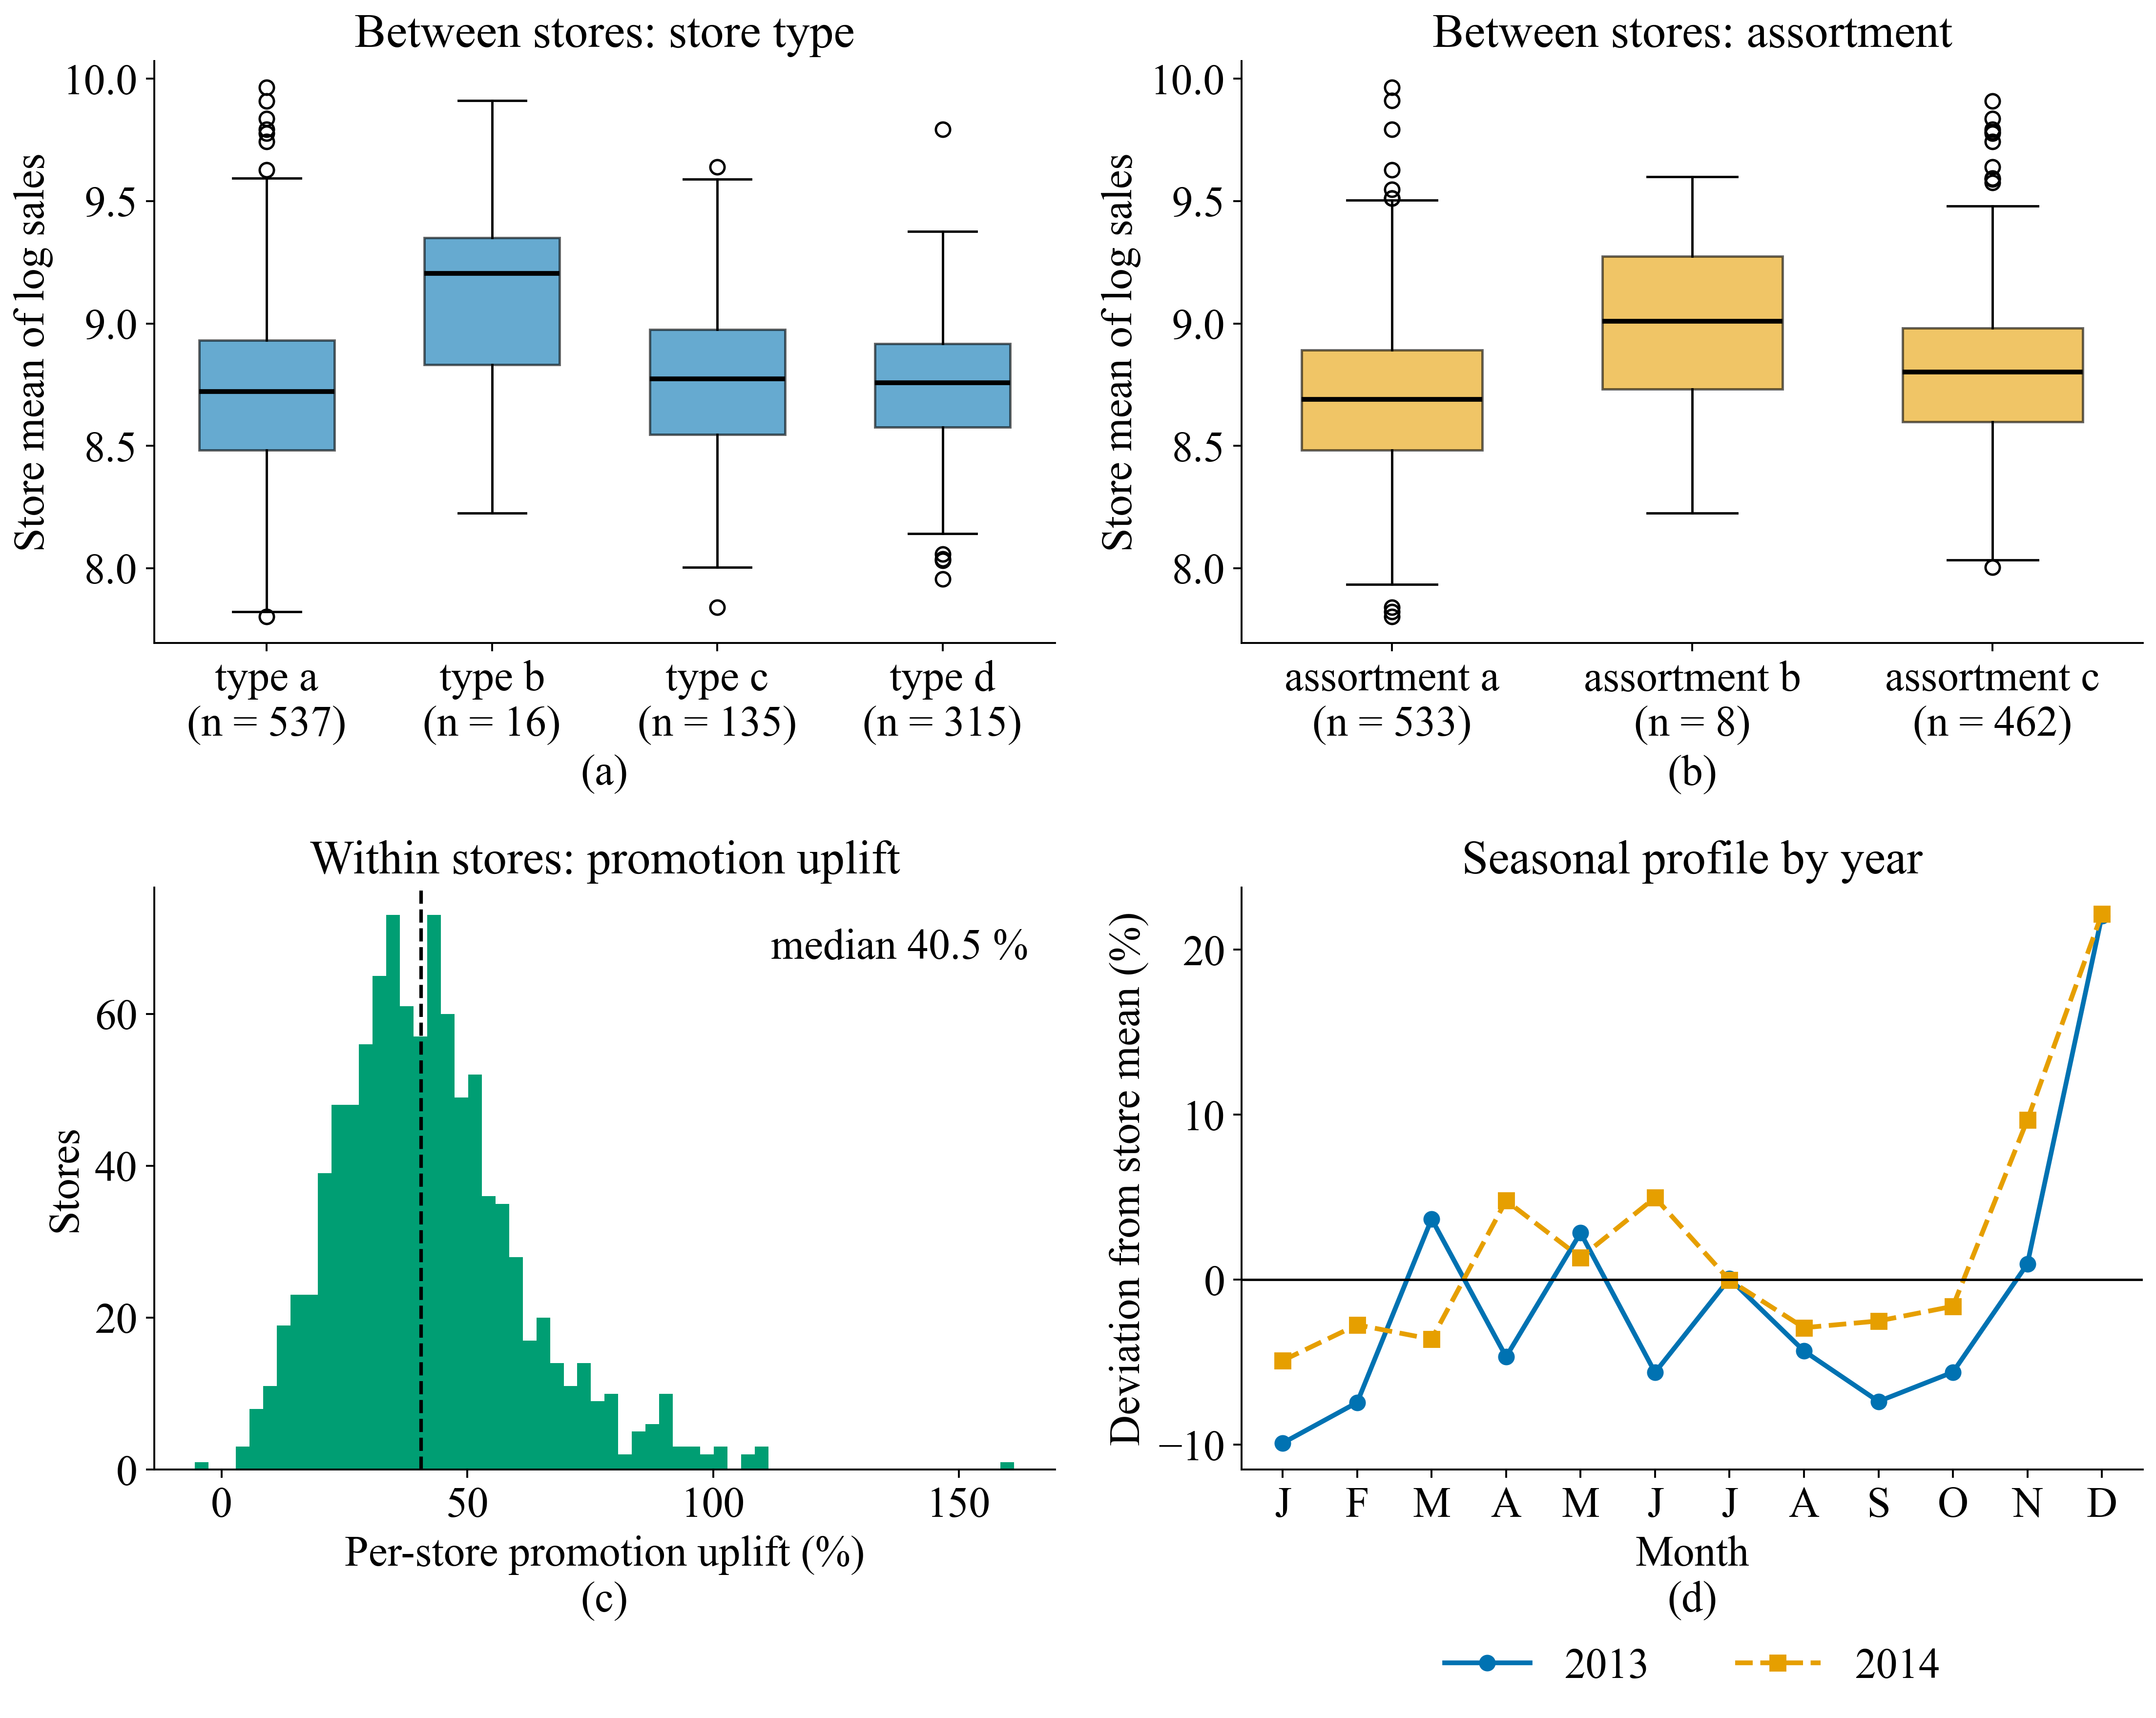

In [16]:
order_t = ["a", "b", "c", "d"]
order_a = ["a", "b", "c"]
uplift = (
    dev_ret.groupby(["Store", "Promo"])["log_sales"].mean().unstack("Promo").dropna()
)
uplift = 100 * (np.exp(uplift[1] - uplift[0]) - 1)
month_prof = (
    sm[sm["year"] <= 2014].groupby(["year", "month"])["dev_log"].mean().unstack("year")
)
fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))
ax = axes[0, 0]
ax.boxplot(
    [store_lvl.loc[store_lvl["StoreType"] == t, "mean_log"] for t in order_t],
    tick_labels=[
        f"type {t}\n(n = {(store_lvl['StoreType'] == t).sum()})" for t in order_t
    ],
    widths=0.6,
    patch_artist=True,
    boxprops={"facecolor": PALETTE[0], "alpha": 0.6},
    medianprops={"color": "black", "lw": 2},
)
ax.set_ylabel("Store mean of log sales")
ax.set_title("Between stores: store type")
ax = axes[0, 1]
ax.boxplot(
    [store_lvl.loc[store_lvl["Assortment"] == a, "mean_log"] for a in order_a],
    tick_labels=[
        f"assortment {a}\n(n = {(store_lvl['Assortment'] == a).sum()})" for a in order_a
    ],
    widths=0.6,
    patch_artist=True,
    boxprops={"facecolor": PALETTE[1], "alpha": 0.6},
    medianprops={"color": "black", "lw": 2},
)
ax.set_ylabel("Store mean of log sales")
ax.set_title("Between stores: assortment")
ax = axes[1, 0]
ax.hist(uplift, bins=60, color=PALETTE[2], edgecolor="none")
ax.axvline(uplift.median(), color="black", ls="--", lw=1.5)
ax.text(
    0.97,
    0.93,
    f"median {uplift.median():.1f} %",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=18,
)
ax.set_xlabel("Per-store promotion uplift (%)")
ax.set_ylabel("Stores")
ax.set_title("Within stores: promotion uplift")
ax = axes[1, 1]
for i, yv in enumerate(month_prof.columns):
    ax.plot(
        month_prof.index,
        100 * (np.exp(month_prof[yv]) - 1),
        marker=["o", "s"][i],
        ls=["-", "--"][i],
        lw=2,
        color=PALETTE[i],
        label=str(yv),
    )
ax.axhline(0, color="black", lw=1)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_xlabel("Month")
ax.set_ylabel("Deviation from store mean (%)")
ax.set_title("Seasonal profile by year")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2)
label_panels(axes)
fig.tight_layout()
save_fig(fig, "fig1_4_group_differences")
show_fig("fig1_4_group_differences", width=1500)
store_lvl.to_csv(TABLES / "fig1_4_store_profiles_numeric.csv", index=True)
uplift.to_csv(TABLES / "fig1_4_promotion_uplift_numeric.csv", header=["uplift_pct"])
month_prof.to_csv(TABLES / "fig1_4_month_profiles_log_numeric.csv")


## 6. Temporal coverage and dependence of observations

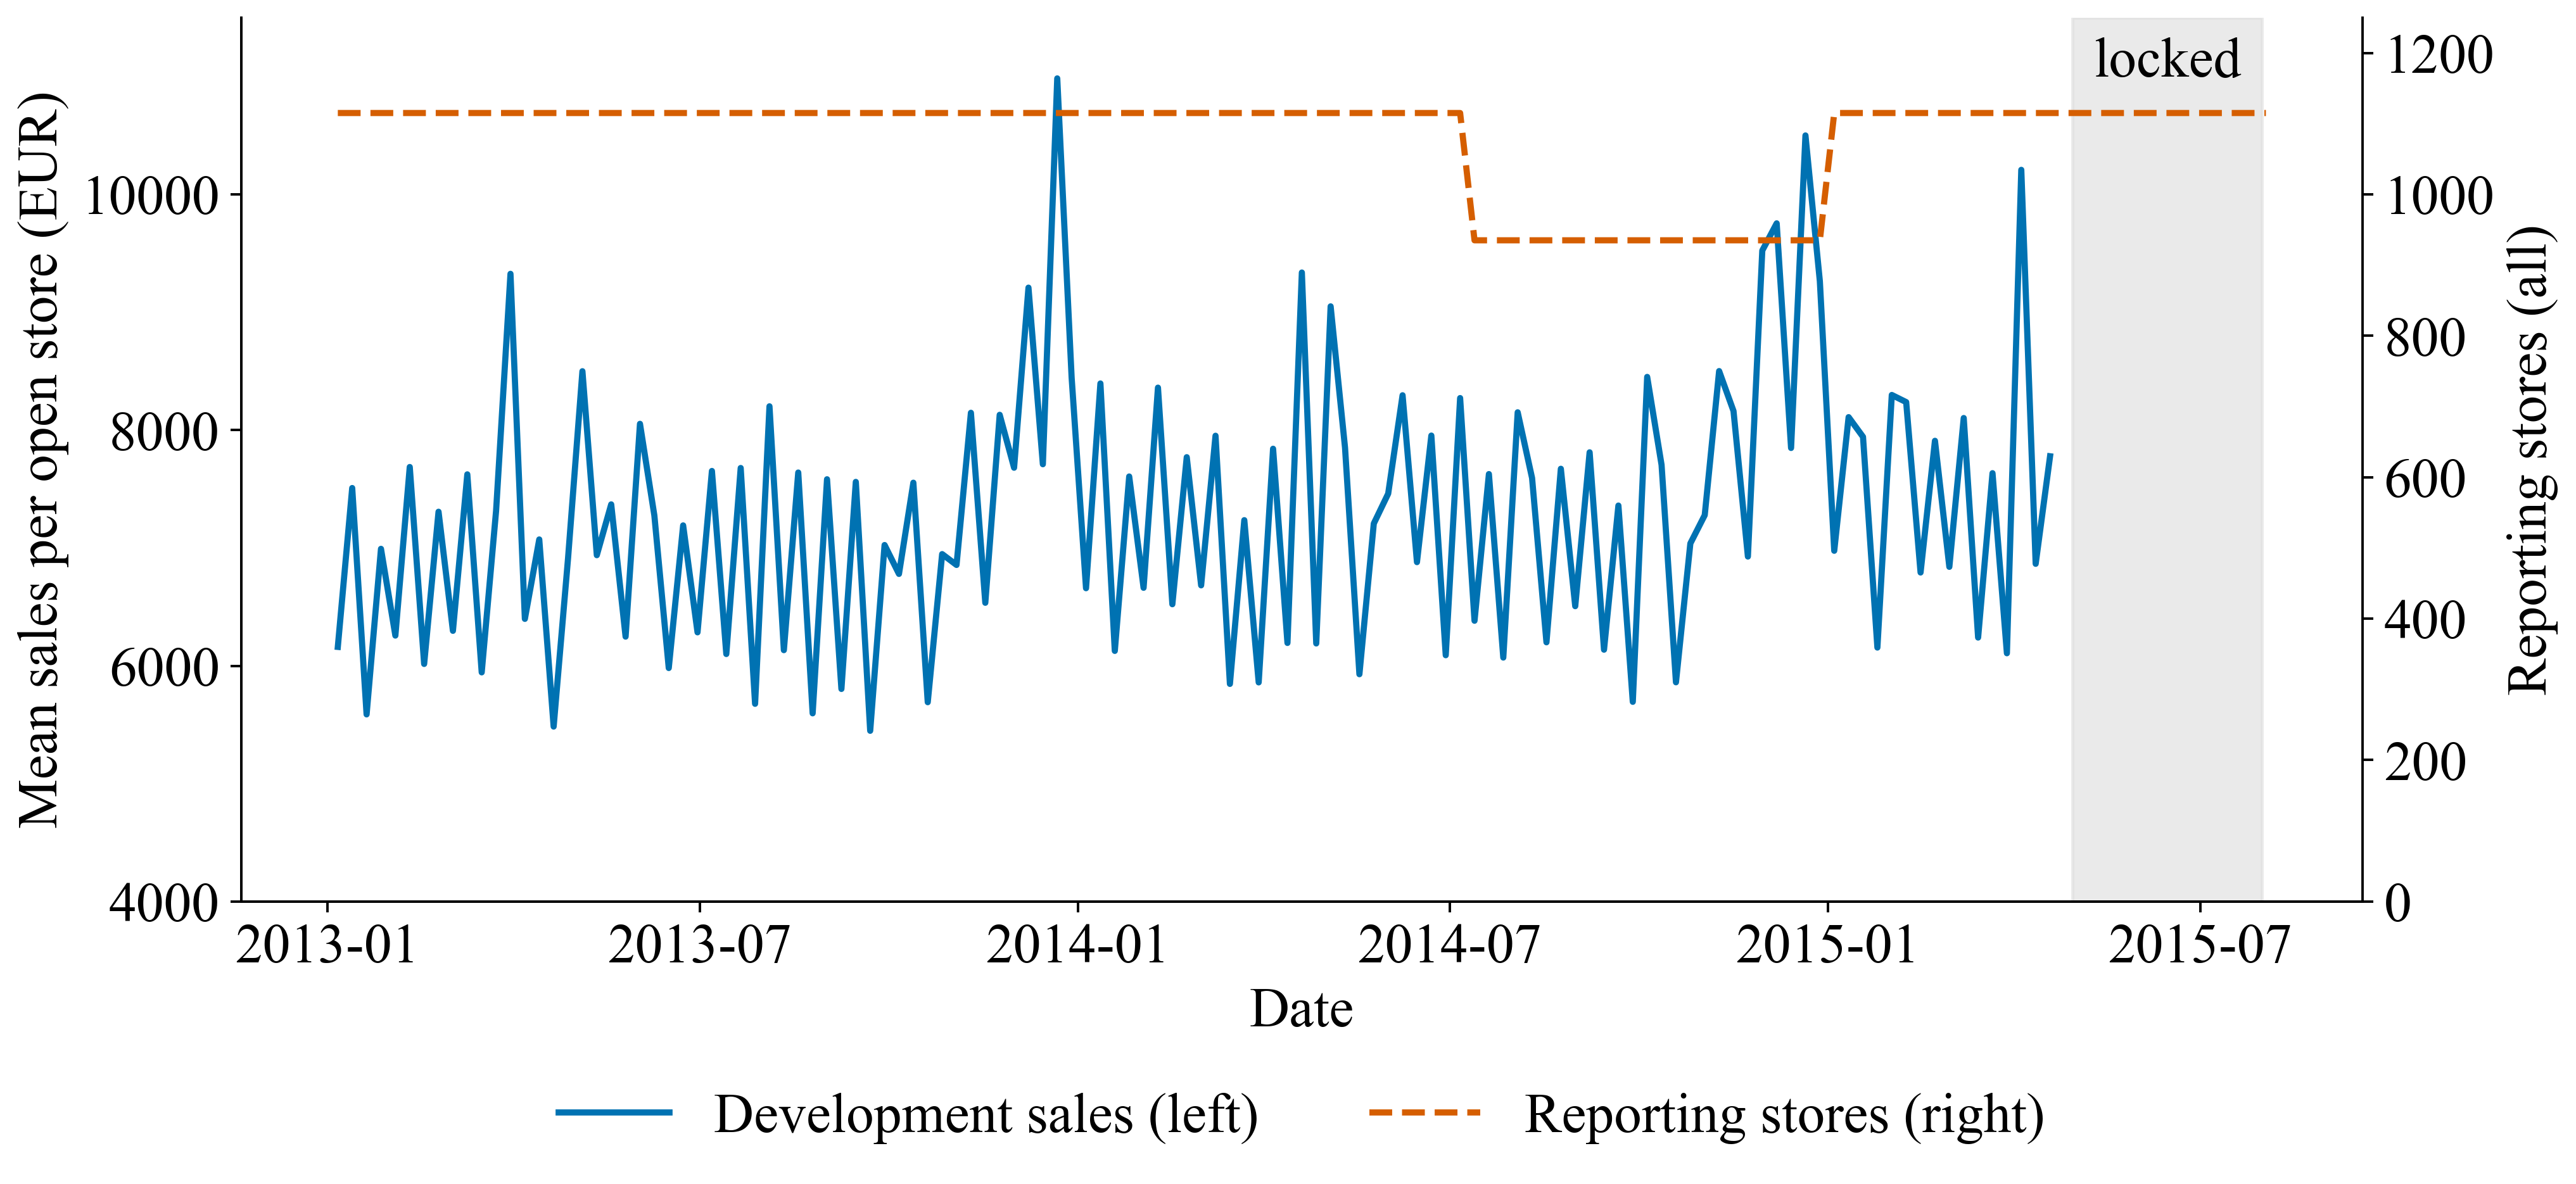

In [17]:
daily = dev_ret.groupby("Date").agg(mean_sales=("Sales", "mean")).reset_index()
reporting = (
    ross.groupby("Date").agg(stores=("Store", "nunique")).reset_index()
)  # record counts only (no target) over the full span
weekly = (
    daily.set_index("Date")
    .resample("W-SUN")
    .agg(mean_sales=("mean_sales", "mean"))
    .reset_index()
)
weekly = weekly[weekly["Date"] <= pd.Timestamp(design["selection_label_cutoff"])]
weekly_rep = (
    reporting.set_index("Date")
    .resample("W-SUN")
    .agg(stores=("stores", "max"))
    .reset_index()
)
fig, ax1 = plt.subplots(figsize=(12, 5.8))
ax1.plot(
    weekly["Date"],
    weekly["mean_sales"],
    color=PALETTE[0],
    lw=2.0,
    label="Development sales (left)",
)
ax1.set_ylabel("Mean sales per open store (EUR)")
ax1.set_xlabel("Date")
ax1.set_ylim(4000, 11500)
ax1.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax1.axvspan(
    pd.Timestamp(BOUNDS["valid_end"]),
    pd.Timestamp(BOUNDS["test_end"]),
    color="#DDDDDD",
    alpha=0.6,
)
ax1.text(pd.Timestamp("2015-06-15"), 11000, "locked", ha="center", fontsize=18)
ax2 = ax1.twinx()
ax2.spines["right"].set_visible(True)
ax2.plot(
    weekly_rep["Date"],
    weekly_rep["stores"],
    color=PALETTE[3],
    lw=2.0,
    ls="--",
    label="Reporting stores (right)",
)
ax2.set_ylabel("Reporting stores (all)")
ax2.set_ylim(0, 1250)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(
    h1 + h2,
    l1 + l2,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    frameon=False,
    ncol=2,
)
fig.tight_layout()
save_fig(fig, "fig1_5_temporal_coverage")
show_fig("fig1_5_temporal_coverage")
weekly.to_csv(TABLES / "fig1_5_development_weekly_sales_numeric.csv", index=False)
weekly_rep.to_csv(TABLES / "fig1_5_all_store_reporting_numeric.csv", index=False)


In [18]:
days_tab = (
    days_per_store.value_counts()
    .rename_axis("recorded days per store")
    .to_frame("stores")
    .sort_index()
)
save_table(
    days_tab,
    "tab1_11_days_per_store",
    "Number of recorded days per store over the full span; 180 stores lack the second half of 2014.",
    float_format="%.0f",
)


,stores
recorded days per store,
758,180
941,1
942,934


In [19]:
wide = dev_ret.pivot(index="Date", columns="Store", values="log_sales").reindex(
    pd.date_range(dev_ret["Date"].min(), dev_ret["Date"].max(), freq="D")
)
W = wide.to_numpy()
obs = ~np.isnan(W)
tot_var = np.nanvar(W)
store_eff = np.nanmean(W, axis=0)  # store intercepts
between_store = np.var(np.broadcast_to(store_eff[None, :], W.shape)[obs]) / tot_var
demeaned = wide - wide.mean()
day_eff = demeaned.mean(
    axis=1
).to_numpy()  # common day effects after removing store intercepts
between_day = np.var(np.broadcast_to(day_eff[:, None], W.shape)[obs]) / tot_var


def pooled_acf(lag):
    a, b = demeaned.to_numpy()[lag:], demeaned.to_numpy()[:-lag]
    m = ~np.isnan(a) & ~np.isnan(b)
    return float(np.corrcoef(a[m], b[m])[0, 1])


dep = pd.DataFrame(
    {
        "value": [
            between_store,
            between_day,
            pooled_acf(1),
            pooled_acf(7),
            pooled_acf(14),
            pooled_acf(28),
            pooled_acf(364),
        ],
        "meaning": [
            "share of log-sales variance between stores (store-level intercepts)",
            "share of log-sales variance between calendar days (common shocks)",
            "within-store autocorrelation of log sales, lag 1 day",
            "lag 7 (same weekday, first usable lag; opposite phase of the fortnightly promotion cycle)",
            "lag 14 (same weekday and promotion phase)",
            "lag 28",
            "lag 364 (same weekday one year earlier)",
        ],
    },
    index=[
        "between-store share",
        "between-day share",
        "ACF(1)",
        "ACF(7)",
        "ACF(14)",
        "ACF(28)",
        "ACF(364)",
    ],
)
save_table(
    dep,
    "tab1_12_dependence_structure",
    "Dependence of observations: variance shares of store and day effects and within-store autocorrelation of log sales (development data).",
    float_format="%.3f",
)


,value,meaning
between-store share,0.5788,share of log-sales variance between stores (store-level intercepts)
between-day share,0.2617,share of log-sales variance between calendar days (common shocks)
ACF(1),0.5764,"within-store autocorrelation of log sales, lag 1 day"
ACF(7),0.1406,"lag 7 (same weekday, first usable lag; opposite phase of the fortnightly promotion cycle)"
ACF(14),0.6132,lag 14 (same weekday and promotion phase)
ACF(28),0.5323,lag 28
ACF(364),0.5539,lag 364 (same weekday one year earlier)


In [21]:
latest_path = MANIFESTS / "latest_runs.json"
latest = json.loads(latest_path.read_text()) if latest_path.exists() else {}
latest["NB01"] = RUN_ID
latest_path.write_text(json.dumps(latest, indent=2));

# Part B · UCI Sales Transactions Weekly

In [1]:
import json,hashlib,csv,zipfile,io
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'uci';RAW=ROOT/'dataset'/'raw'/'UCI_SalesTransactionsWeekly'/'source.zip'
RUN_ID='NB01_UCI_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
for sub in 'Configs Data Manifests'.split():(BASE/sub).mkdir(parents=True,exist_ok=True)
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_rows',120,'display.max_columns',12,'display.max_colwidth',None,'display.float_format',lambda v:f'{v:.5f}')
def table(df,name):
    df.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(df.to_latex(index=False,float_format='%.5f',escape=True));display(df)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))


## Schema and product allocation before outcome access

In [2]:
with zipfile.ZipFile(RAW) as z:
    entries=z.namelist();csvs=[n for n in entries if n.lower().endswith('.csv')];assert len(csvs)==1
    MEMBER=csvs[0]
    with z.open(MEMBER) as stream:
        reader=csv.reader(io.TextIOWrapper(stream,encoding='utf-8-sig'));HEADER=next(reader);id_col=HEADER.index('Product_Code');IDS=[row[id_col] for row in reader if row]
assert len(IDS)==len(set(IDS)) and all(str(x).strip() for x in IDS),'Ambiguous product identifiers'
assert all('W'+str(w) in HEADER for w in range(52));assert len(HEADER)==len(set(HEADER))
order=sorted(IDS,key=lambda x:hashlib.sha256(('assem-uci-external-2026:'+x).encode()).hexdigest());external_n=int(np.ceil(.1*len(order)))
EXTERNAL=set(order[:external_n]);CORE=set(order[external_n:]);assert not EXTERNAL&CORE and EXTERNAL|CORE==set(IDS)
allocation=pd.DataFrame([{'Product_Code':x,'cohort':'external' if x in EXTERNAL else 'core','hash_key':hashlib.sha256(('assem-uci-external-2026:'+x).encode()).hexdigest()} for x in sorted(IDS)])
allocation.to_csv(BASE/'Configs/product_allocation.csv',index=False)
STRUCTURE={'csv_member':MEMBER,'source_columns':len(HEADER),'products':len(IDS),'core_products':len(CORE),'external_products':len(EXTERNAL),'raw_weeks':52,'train_weeks':[0,27],'initial_fit_latest_week':26,'reserved_development_weeks':[28,39],'selection_weeks':[28,38],'uninspected_gap_week':39,'locked_test_weeks':[40,51],'latest_available_week_offset':-2}
(BASE/'Configs/study_design.json').write_text(json.dumps(STRUCTURE,indent=2))
forbidden=[c for c in HEADER if c not in ['Product_Code']+['W'+str(w) for w in range(52)]]
table(pd.DataFrame([{'Item':'Product IDs','Count':len(IDS)},{'Item':'Core products','Count':len(CORE)},{'Item':'External products; targets sealed','Count':len(EXTERNAL)},{'Item':'Raw weekly columns','Count':52},{'Item':'Excluded normalized or whole-series columns','Count':len(forbidden)}]),'schema_and_cohorts')
table(pd.DataFrame({'Excluded column':forbidden}), 'forbidden_columns')


,Item,Count
0,Product IDs,811
1,Core products,729
2,External products; targets sealed,82
3,Raw weekly columns,52
4,Excluded normalized or whole-series columns,54


,Excluded column
0,MIN
1,MAX
2,Normalized 0
3,Normalized 1
4,Normalized 2
5,Normalized 3
6,Normalized 4
7,Normalized 5
8,Normalized 6
9,Normalized 7


## Permitted core outcomes and data-quality checks

In [3]:
# Materialize only core-product W0–W38. Never retain external, W39, W40–W51, MIN/MAX or normalized values.
ALLOWED_WEEKS=list(range(39));positions=[HEADER.index('W'+str(w)) for w in ALLOWED_WEEKS];records=[]
with zipfile.ZipFile(RAW) as z:
    with z.open(MEMBER) as stream:
        reader=csv.reader(io.TextIOWrapper(stream,encoding='utf-8-sig'));assert next(reader)==HEADER
        for row in reader:
            if row and row[id_col] in CORE:records.append([row[id_col]]+[row[j] for j in positions])
wide=pd.DataFrame(records,columns=['Product_Code']+['W'+str(w) for w in ALLOWED_WEEKS]).set_index('Product_Code').sort_index()
numeric=wide.apply(pd.to_numeric,errors='coerce');arr=numeric.to_numpy(float)
QUALITY={'core_products':len(wide),'permitted_weeks':len(ALLOWED_WEEKS),'numeric_cells':arr.size,'missing_or_nonnumeric':int(np.isnan(arr).sum()),'nonfinite':int((~np.isfinite(arr)).sum()),'negative':int((arr<0).sum()),'noninteger':int((np.isfinite(arr)&(arr!=np.floor(arr))).sum()),'duplicate_ids':int(wide.index.duplicated().sum())}
table(pd.DataFrame([{'Check':k,'Value':v} for k,v in QUALITY.items()]),'data_quality')
assert QUALITY['missing_or_nonnumeric']==QUALITY['nonfinite']==QUALITY['negative']==QUALITY['noninteger']==QUALITY['duplicate_ids']==0
assert len(wide)==len(CORE)
long=numeric.rename_axis('Product_Code').reset_index().melt(id_vars='Product_Code',var_name='week_name',value_name='quantity');long['week']=long.week_name.str[1:].astype(int);long=long.drop(columns='week_name').sort_values(['week','Product_Code']).reset_index(drop=True)
long['role']=np.select([long.week<=26,long.week==27,long.week>=28],['initial training','delayed training week','selection'],default='invalid')
assert long.week.max()==38 and set(long.Product_Code)==CORE and not long.duplicated(['Product_Code','week']).any()
TRAIN=long[long.week<=26].copy();SELECT=long[long.week>=28].copy()
long.to_parquet(BASE/'Data/core_permitted_long.parquet',index=False)
table(long.groupby('role',sort=False).agg(Products=('Product_Code','nunique'),Weeks=('week','nunique'),Rows=('quantity','size'),Positive_targets=('quantity',lambda x:int((x>0).sum())),Zero_targets=('quantity',lambda x:int((x==0).sum()))).reset_index(),'observed_support')


,Check,Value
0,core_products,729
1,permitted_weeks,39
2,numeric_cells,28431
3,missing_or_nonnumeric,0
4,nonfinite,0
5,negative,0
6,noninteger,0
7,duplicate_ids,0


,role,Products,Weeks,Rows,Positive_targets,Zero_targets
0,initial training,729,27,19683,13691,5992
1,delayed training week,729,1,729,499,230
2,selection,729,11,8019,5598,2421


## Training distributions, zeros and repeated histories

In [4]:
SUMMARY=[]
for label,f in [('Initial training W0–W26',TRAIN),('Selection W28–W38',SELECT)]:
    q=f.quantity;SUMMARY.append({'Period':label,'Rows':len(f),'Mean':q.mean(),'Median':q.median(),'SD':q.std(),'Minimum':q.min(),'Maximum':q.max(),'Zero fraction':(q==0).mean(),'Positive support':int((q>0).sum())})
table(pd.DataFrame(SUMMARY).iloc[:,:8],'quantity_summary');table(pd.DataFrame(SUMMARY)[['Period','Zero fraction','Positive support']],'zero_and_positive_support')
PRODUCT=TRAIN.groupby('Product_Code').quantity.agg(['mean','std','min','max','sum']).reset_index()
PRODUCT['zero_fraction']=TRAIN.groupby('Product_Code').quantity.apply(lambda x:(x==0).mean()).reindex(PRODUCT.Product_Code).to_numpy()
PRODUCT['positive_weeks']=TRAIN.groupby('Product_Code').quantity.apply(lambda x:int((x>0).sum())).reindex(PRODUCT.Product_Code).to_numpy()
histories=numeric[['W'+str(w) for w in range(27)]];duplicates=int(histories.duplicated(keep=False).sum());allzero=int((histories==0).all(axis=1).sum())
qcuts=PRODUCT['mean'].quantile([.25,.5,.75]).to_numpy();PRODUCT['volume_group']=np.searchsorted(qcuts,PRODUCT['mean'],side='right')+1
PRODUCT.to_csv(OUT/'training_product_profile.csv',index=False)
table(pd.DataFrame([{'Check':'Products sharing an identical training history','Count':duplicates},{'Check':'Products with all-zero initial training history','Count':allzero},{'Check':'Products excluded using outcome values','Count':0}]),'training_history_diagnostics')
table(PRODUCT.groupby('volume_group').agg(Products=('Product_Code','size'),Mean_quantity=('mean','mean'),Mean_zero_fraction=('zero_fraction','mean'),Mean_positive_weeks=('positive_weeks','mean')).reset_index(),'training_volume_groups')


,Period,Rows,Mean,Median,SD,Minimum,Maximum,Zero fraction
0,Initial training W0–W26,19683,9.39623,4.00000,12.81778,0,72,0.30443
1,Selection W28–W38,8019,7.64771,3.00000,10.58481,0,55,0.30191


,Period,Zero fraction,Positive support
0,Initial training W0–W26,0.30443,13691
1,Selection W28–W38,0.30191,5598


,Check,Count
0,Products sharing an identical training history,41
1,Products with all-zero initial training history,12
2,Products excluded using outcome values,0


,volume_group,Products,Mean_quantity,Mean_zero_fraction,Mean_positive_weeks
0,1,178,0.12360,0.88847,3.01124
1,2,186,1.73397,0.33771,17.88172
2,3,182,7.72772,0.00529,26.85714
3,4,183,27.86278,0.00000,27.00000


## Figures for distributions and temporal structure

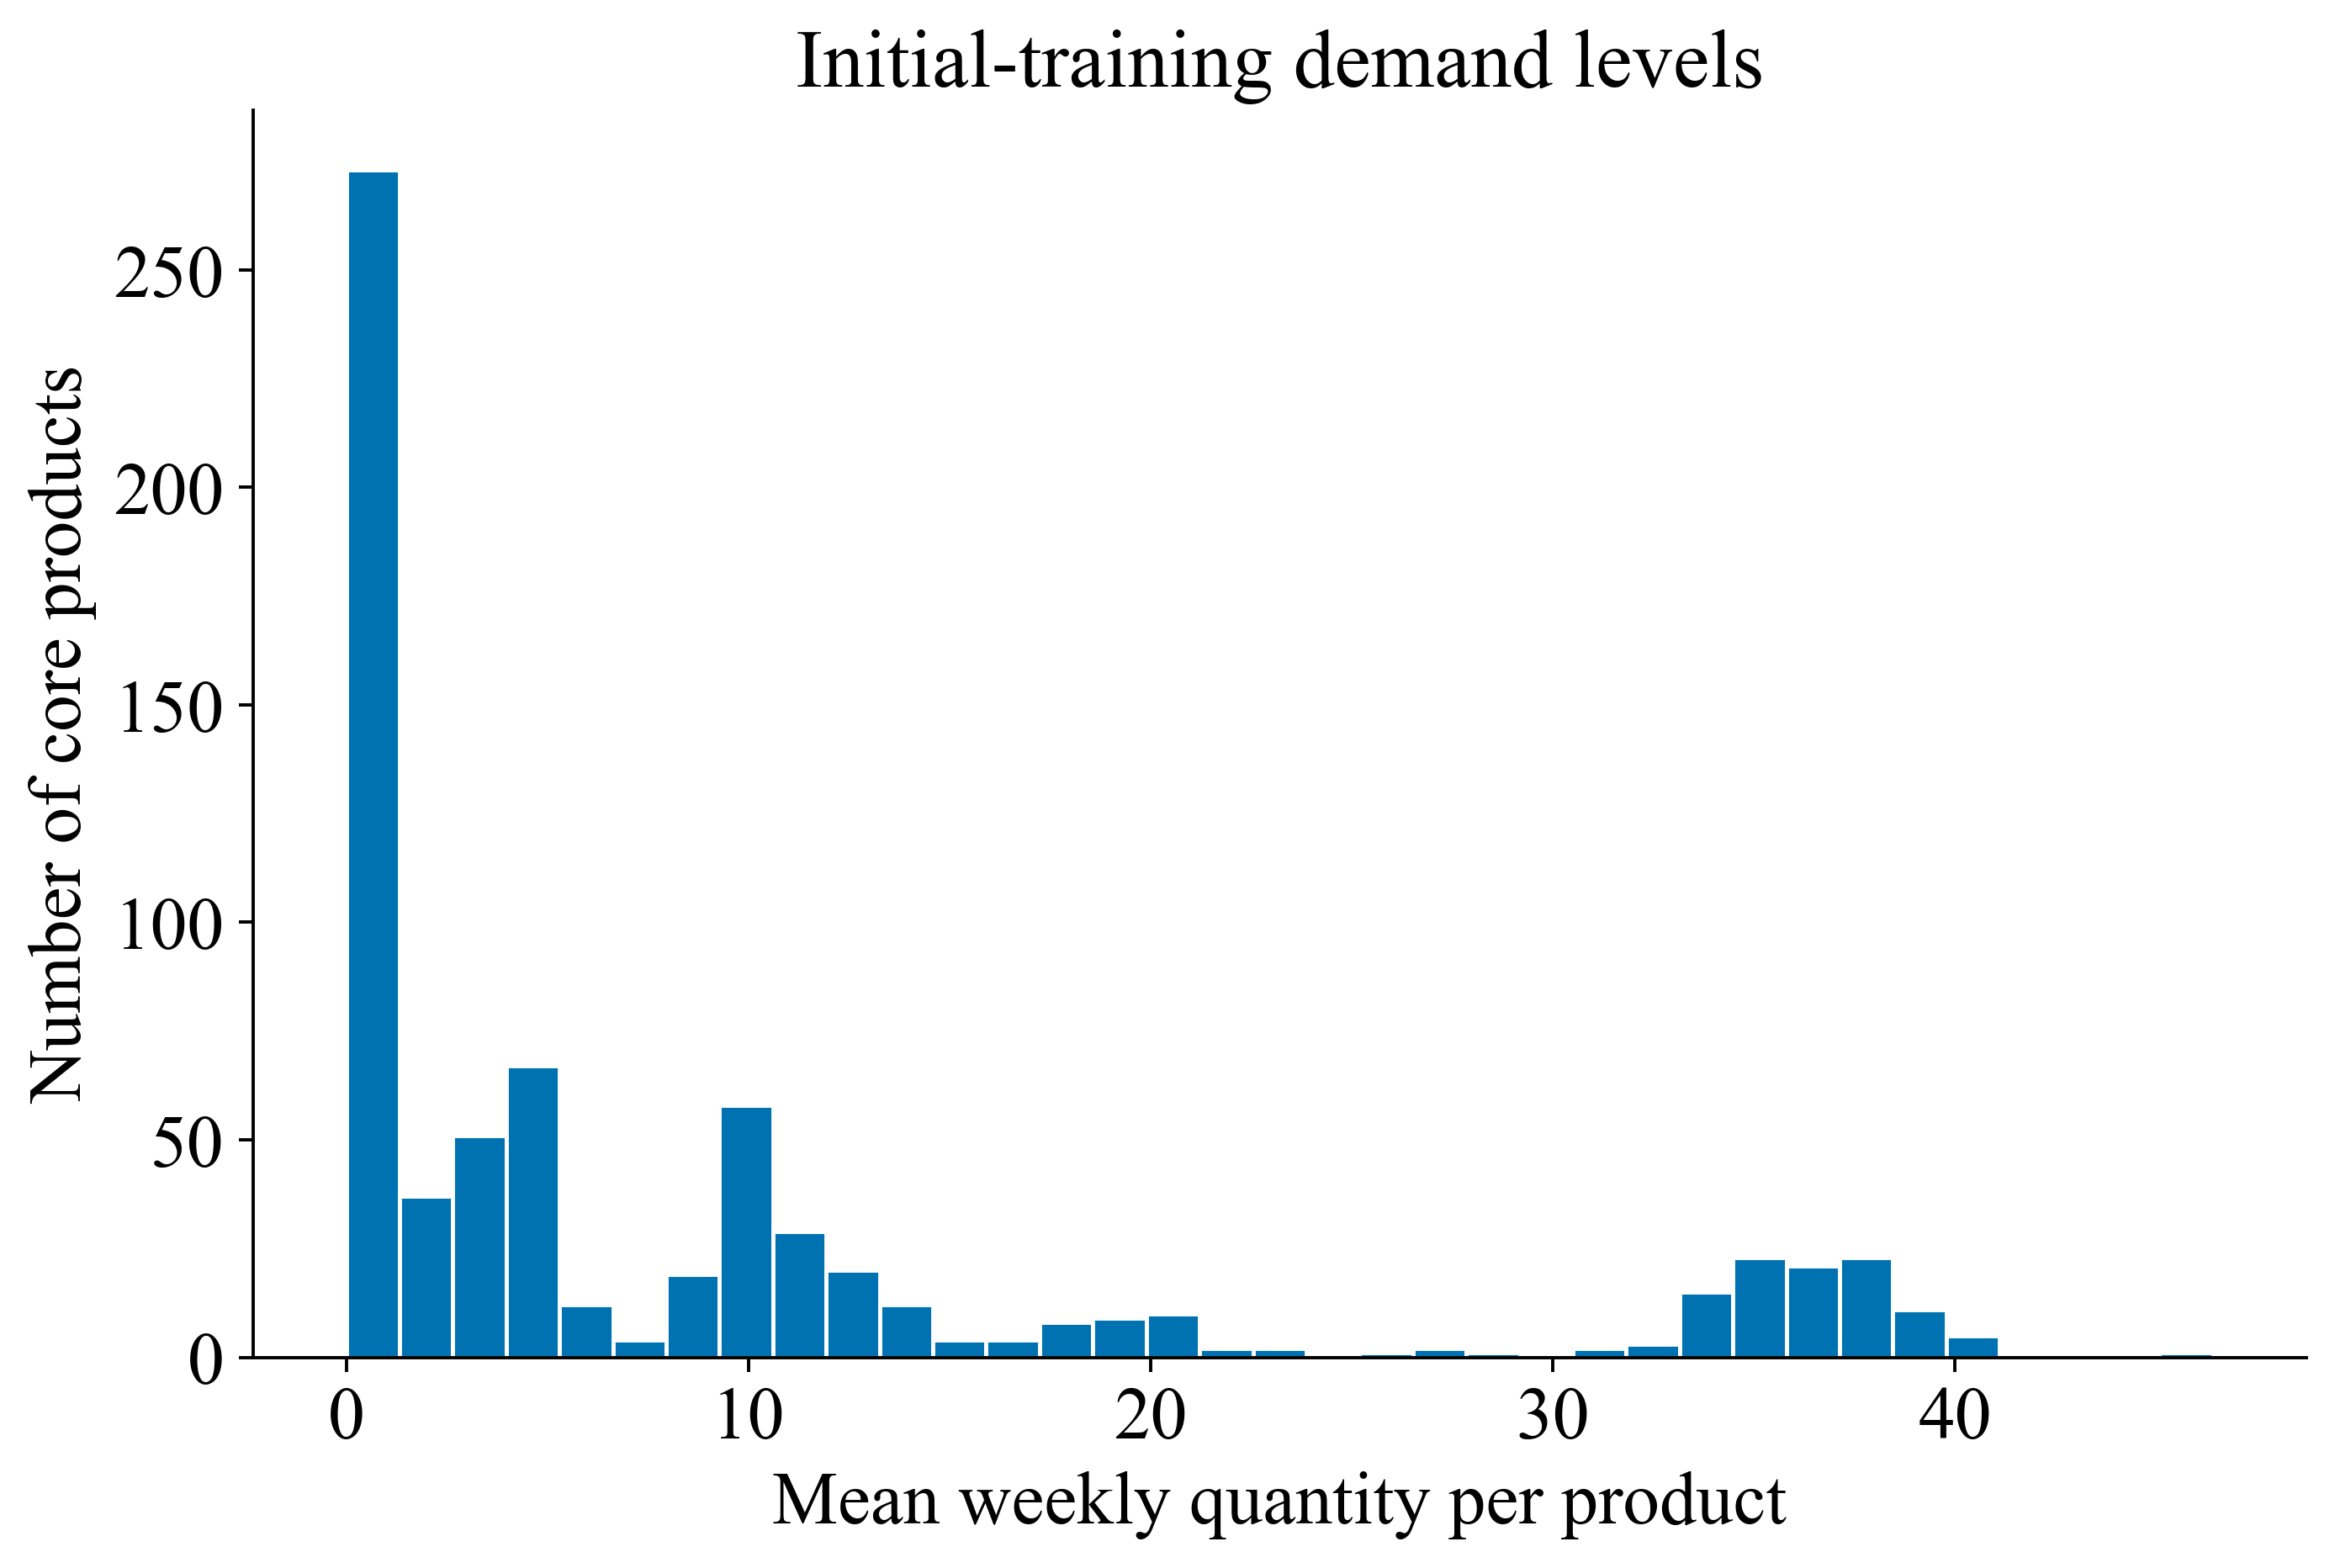

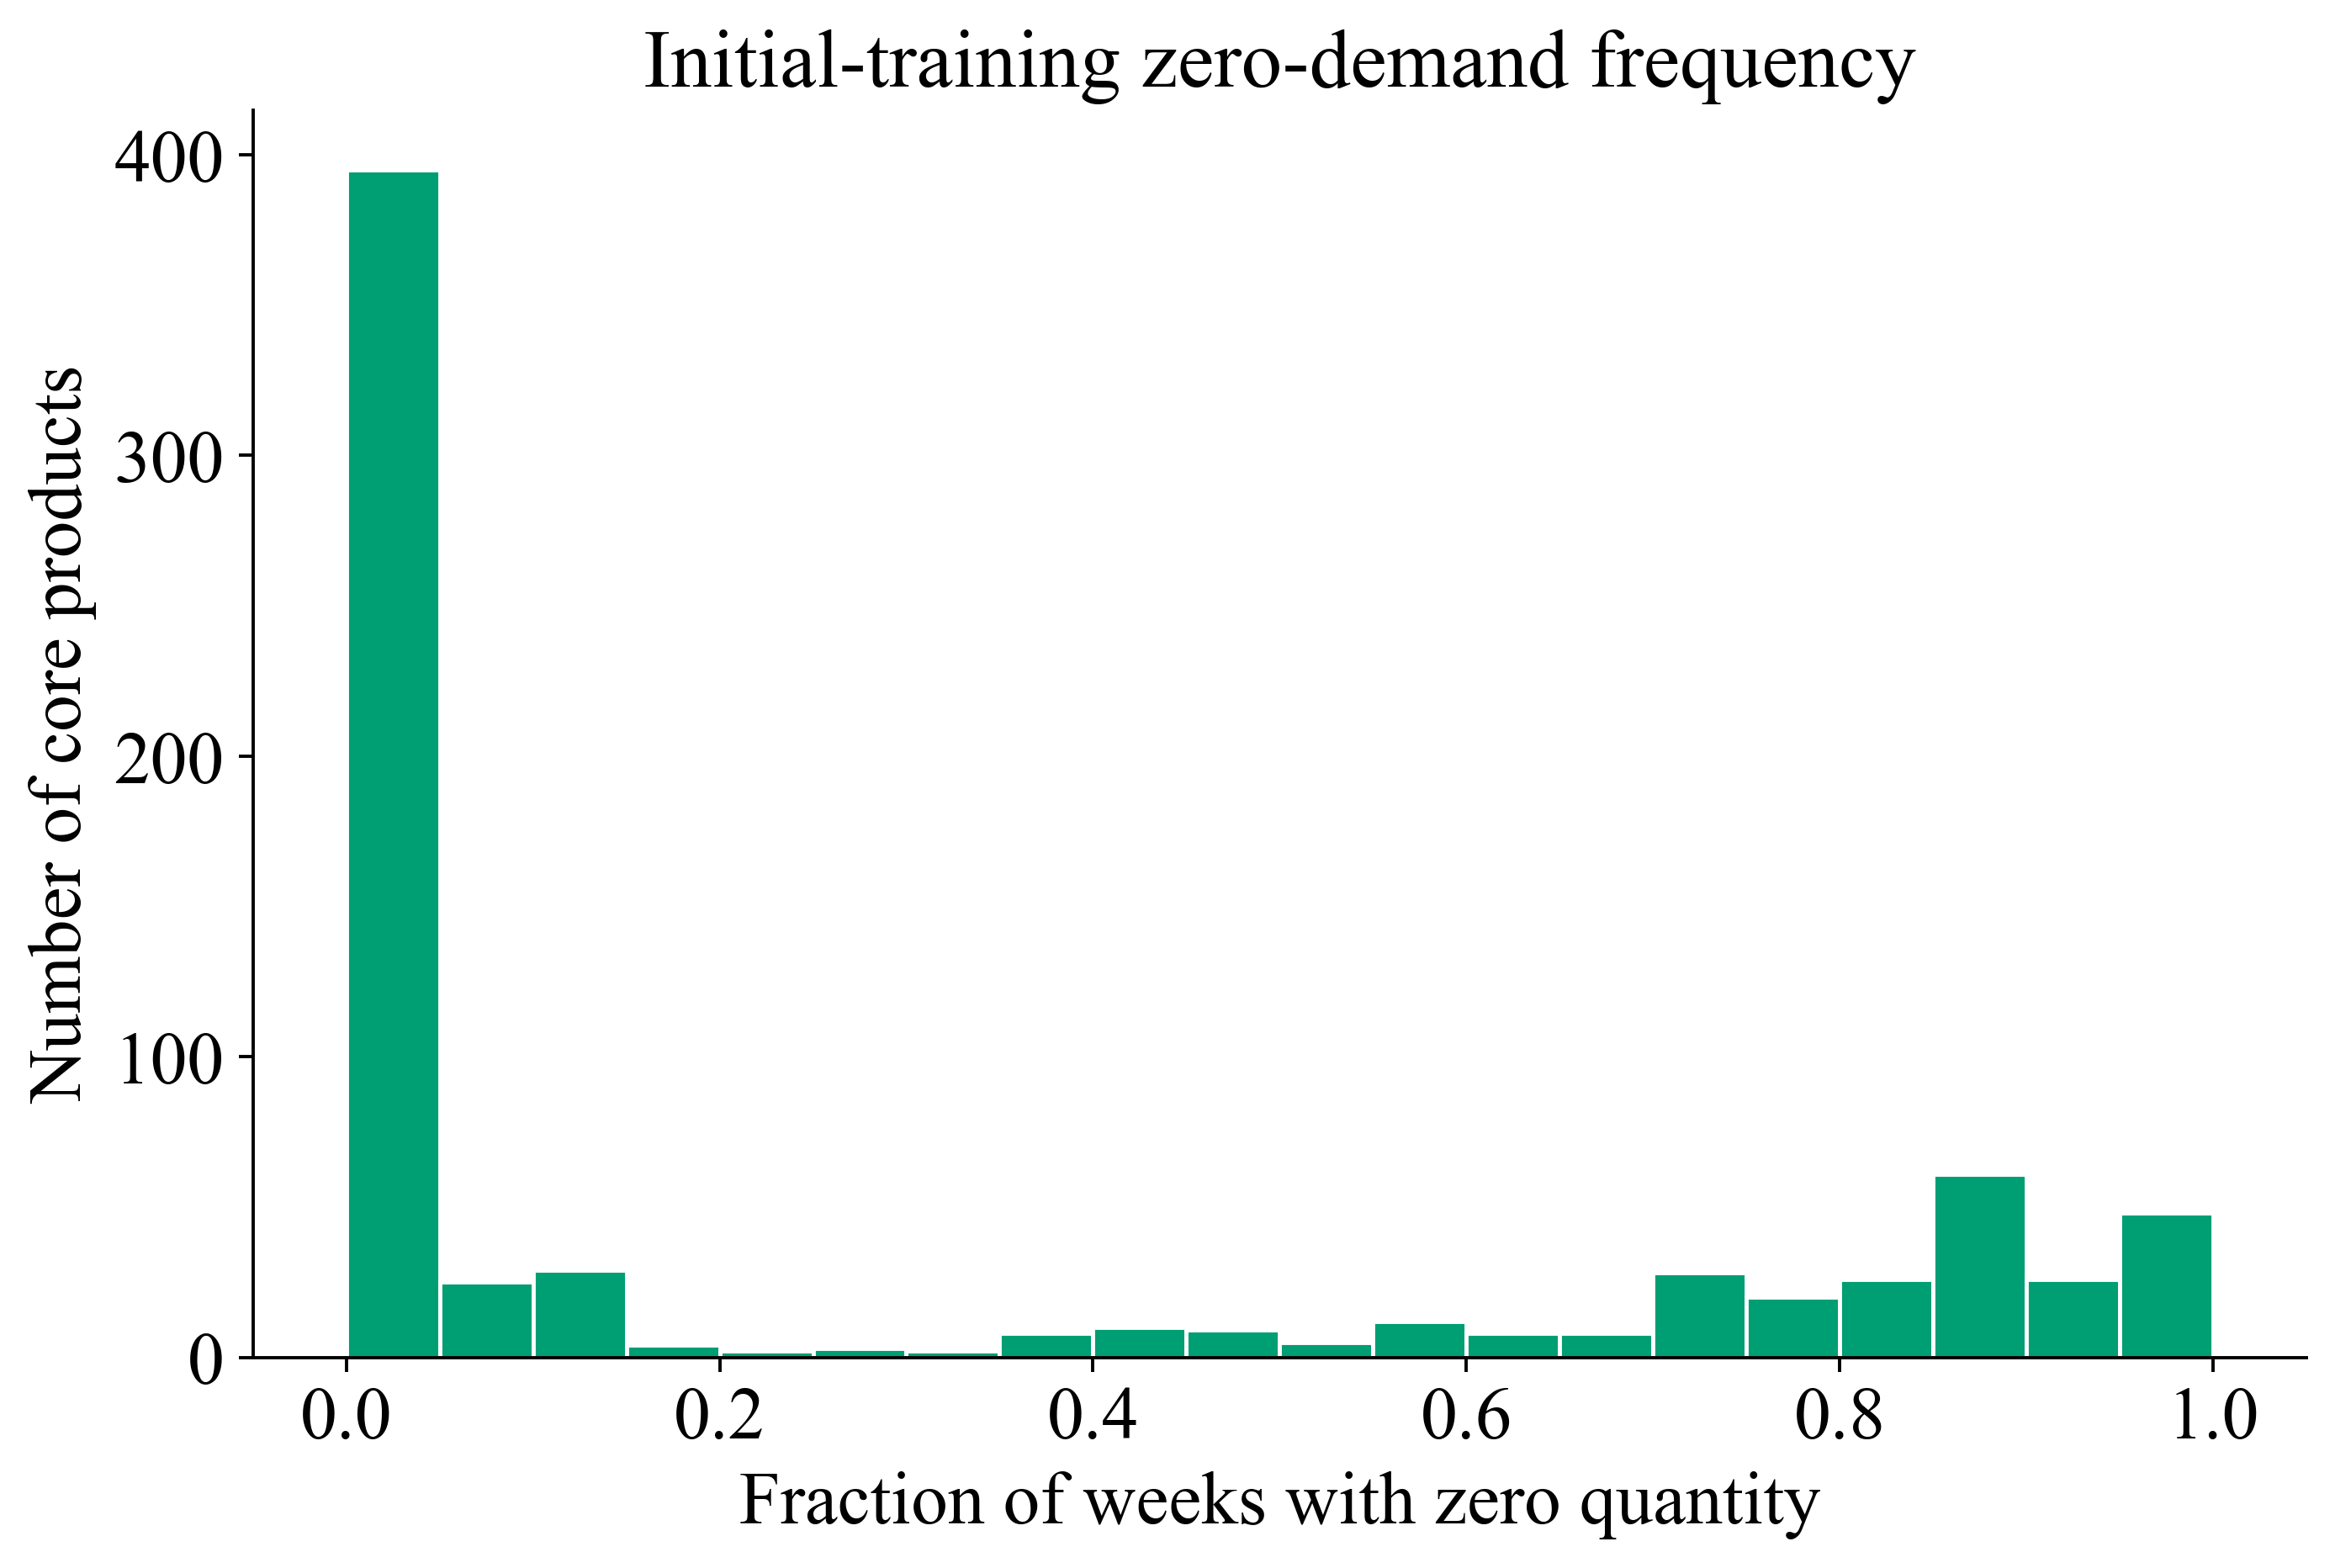

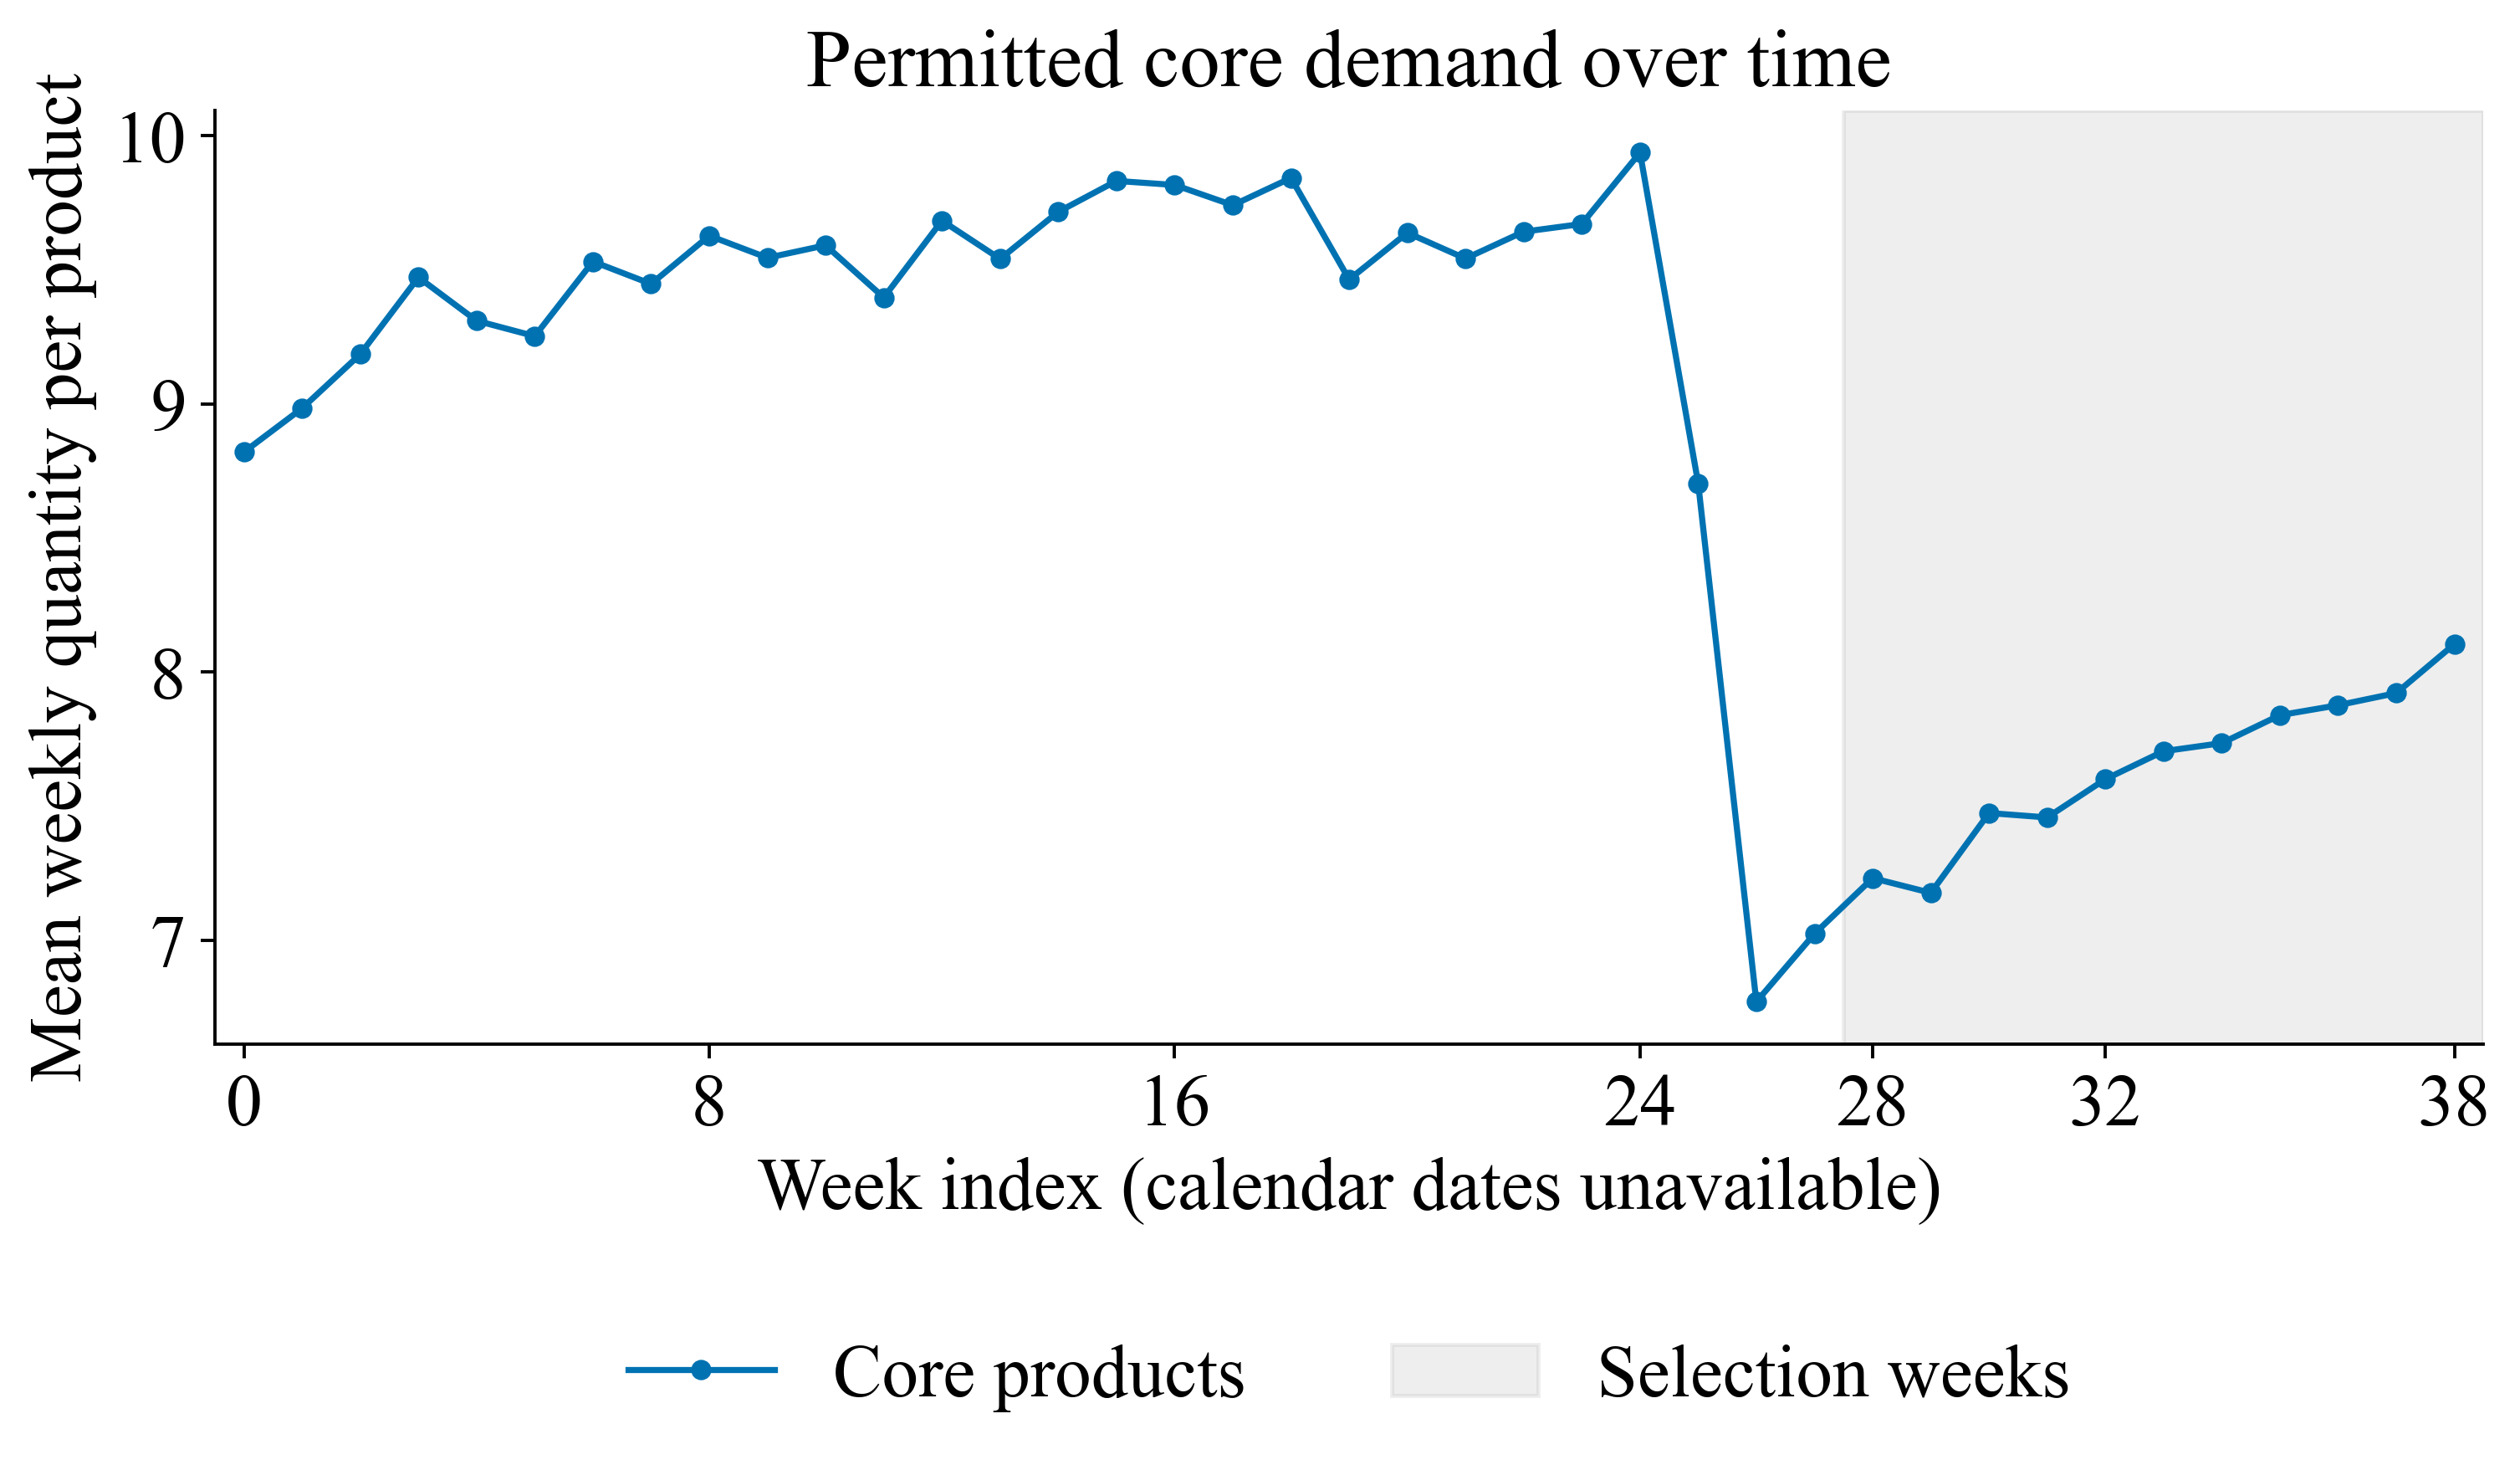

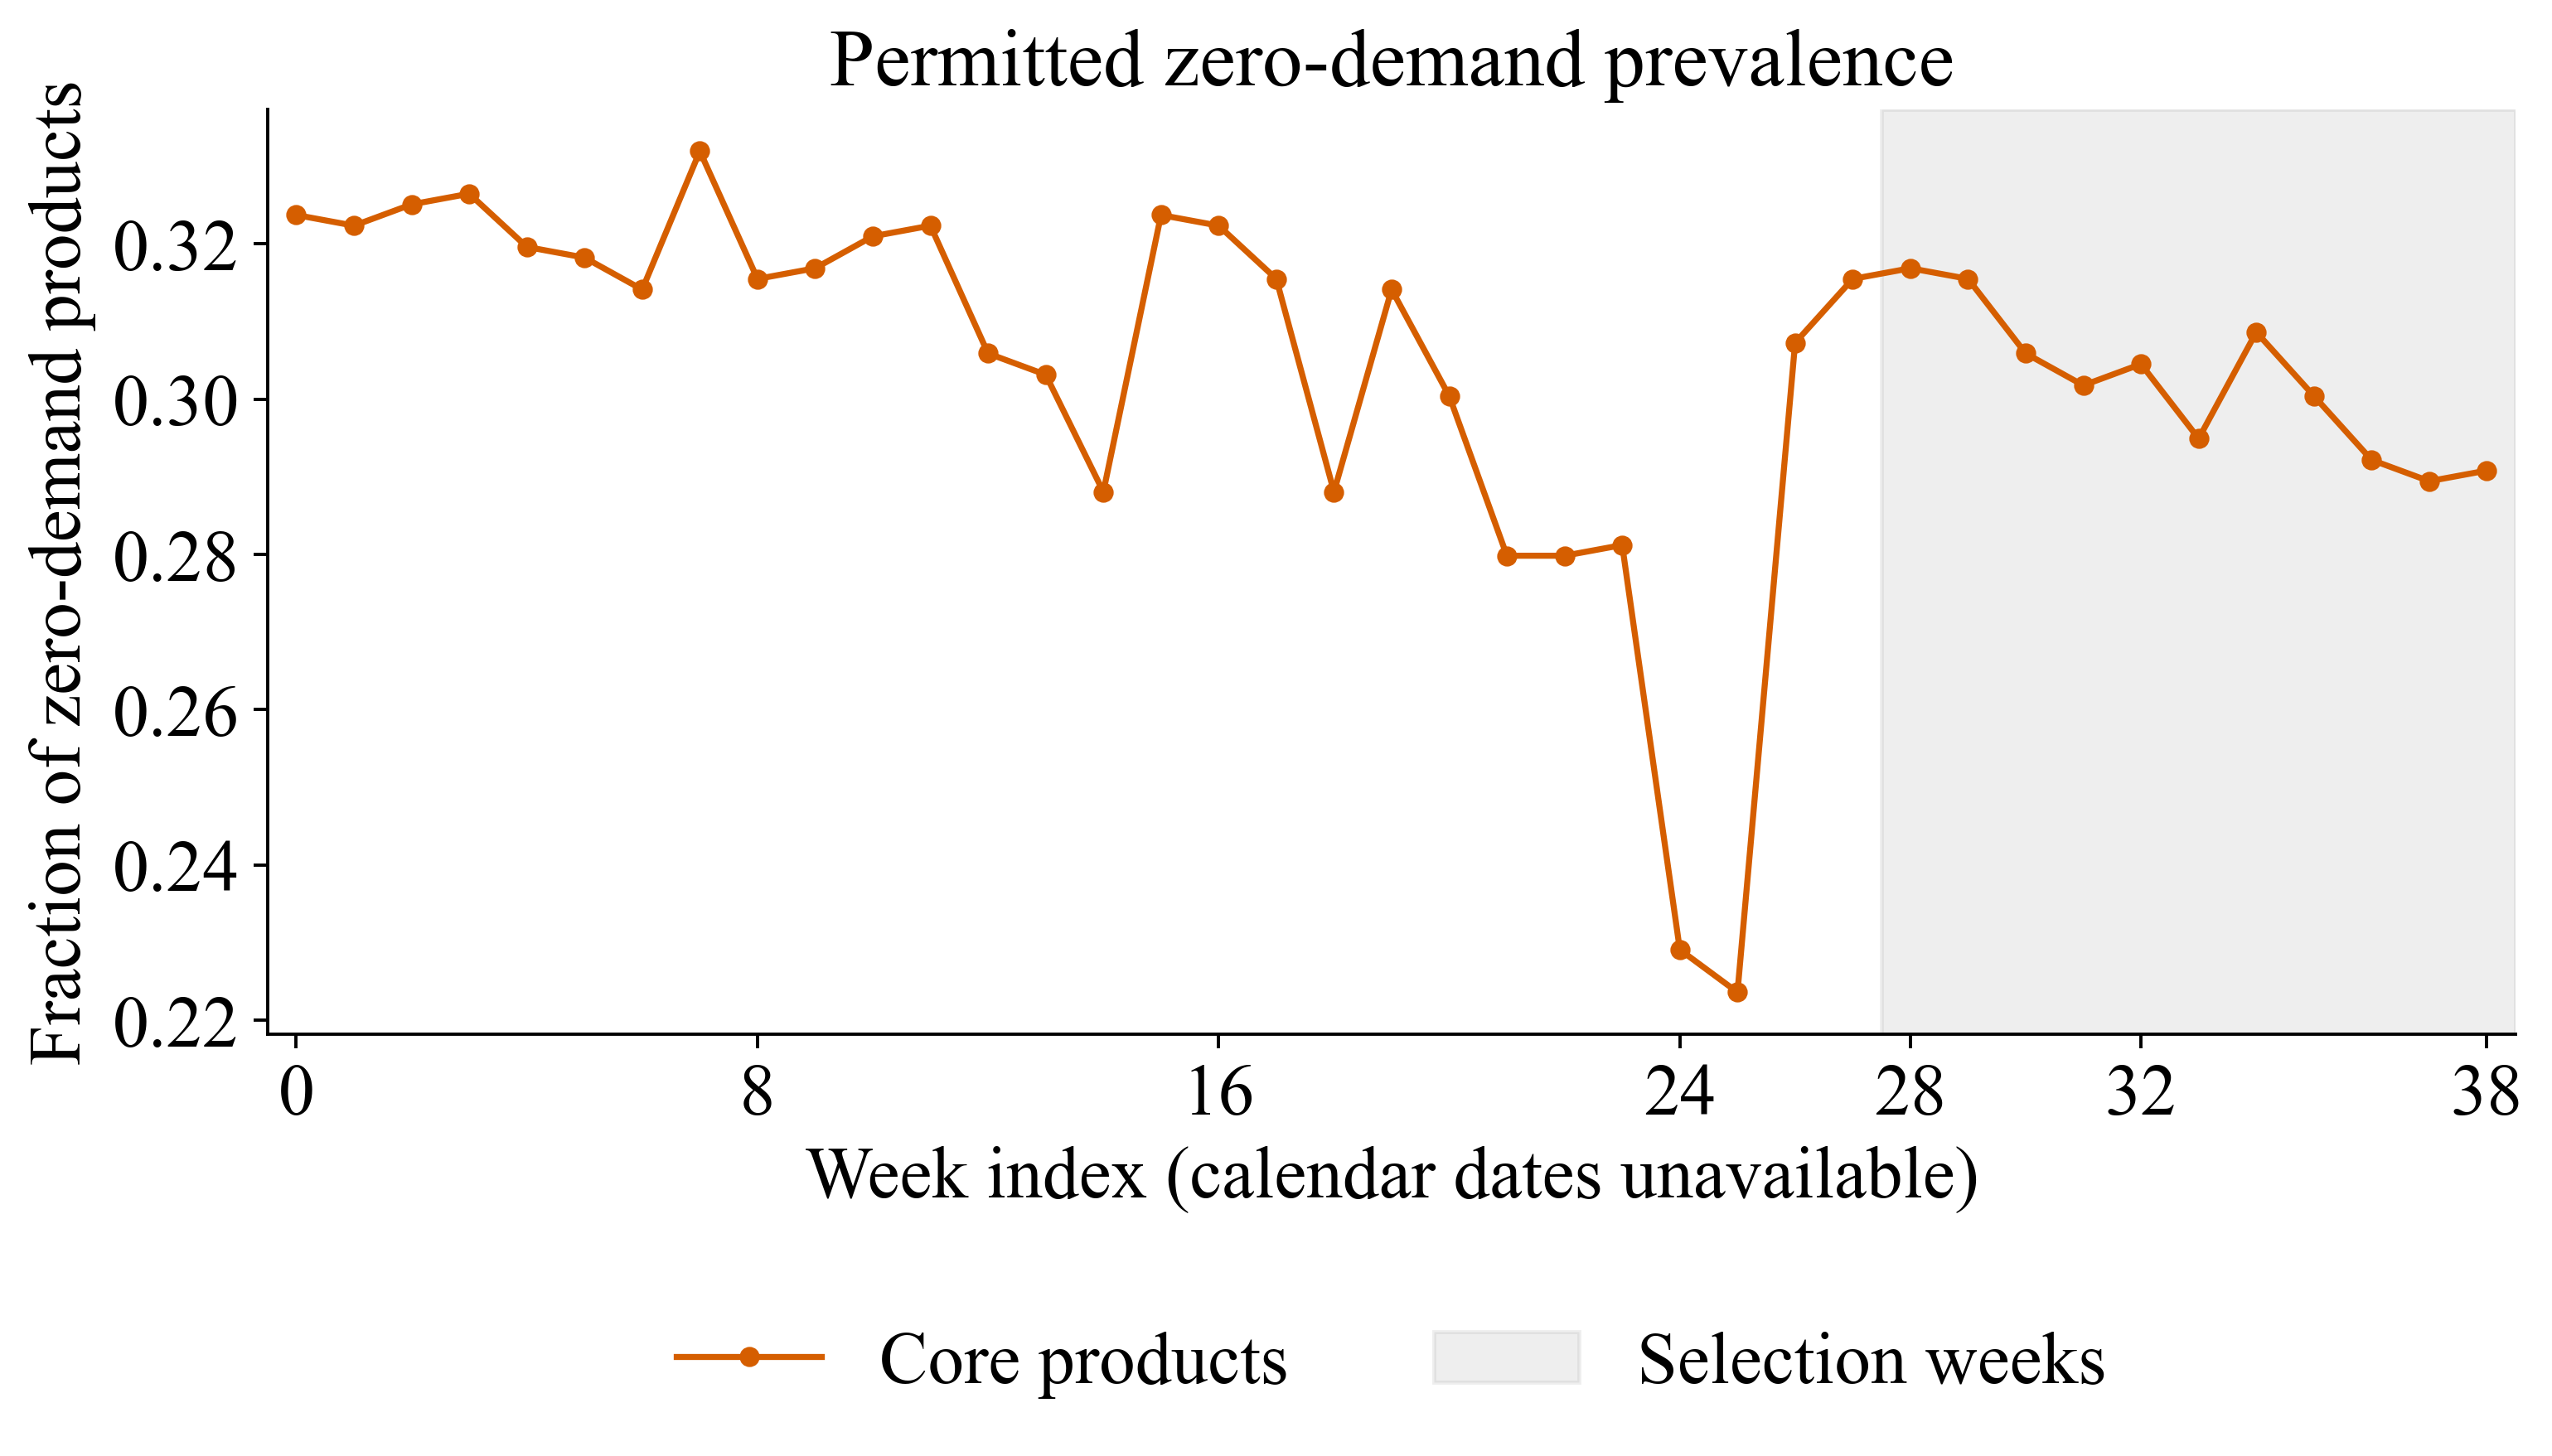

In [5]:
fig,ax=plt.subplots(figsize=(9,5.5));ax.hist(PRODUCT['mean'],bins=35,color='#0072B2',edgecolor='white');ax.set_xlabel('Mean weekly quantity per product');ax.set_ylabel('Number of core products');ax.set_title('Initial-training demand levels');figure(fig,'fig_uci_training_mean')
fig,ax=plt.subplots(figsize=(9,5.5));ax.hist(PRODUCT.zero_fraction,bins=np.linspace(0,1,21),color='#009E73',edgecolor='white');ax.set_xlabel('Fraction of weeks with zero quantity');ax.set_ylabel('Number of core products');ax.set_title('Initial-training zero-demand frequency');figure(fig,'fig_uci_training_zeros')
WEEKLY=long.groupby('week').quantity.agg(['mean','median','sum','size']).reset_index();WEEKLY['zero_fraction']=long.groupby('week').quantity.apply(lambda x:(x==0).mean()).to_numpy();WEEKLY.to_csv(OUT/'weekly_source.csv',index=False)
for column,label,title,name,color in [('mean','Mean weekly quantity per product','Permitted core demand over time','fig_uci_weekly_mean','#0072B2'),('zero_fraction','Fraction of zero-demand products','Permitted zero-demand prevalence','fig_uci_weekly_zeros','#D55E00')]:
    fig,ax=plt.subplots(figsize=(10,5.5));ax.plot(WEEKLY.week,WEEKLY[column],color=color,marker='o',markersize=4,label='Core products')
    ax.axvspan(27.5,38.5,color='#999999',alpha=.16,label='Selection weeks');ax.set_xlim(-.5,38.5);ax.set_xticks([0,8,16,24,28,32,38]);ax.set_xlabel('Week index (calendar dates unavailable)');ax.set_ylabel(label);ax.set_title(title)
    ax.legend(loc='upper center',bbox_to_anchor=(.5,-.25),ncol=2,frameon=False);fig.subplots_adjust(bottom=.3);figure(fig,name)


## Forecast information set and inner folds

In [6]:
POLICIES=pd.DataFrame([
 {'Topic':'Forecast timing','Decision':'At start of week t, predict quantity for t; latest observed quantity is t−2.'},
 {'Topic':'Timing evidence','Decision':'One-week reporting delay is an imposed assumption; source timing is unspecified.'},
 {'Topic':'Primary metric','Decision':'RMSPE on strictly positive targets; report positive support and excluded zero count.'},
 {'Topic':'All-observation quality','Decision':'RMSE and MAE include zeros; sMAPE uses zero for a zero/zero pair.'},
 {'Topic':'Predictive uncertainty','Decision':'Use a distribution with mass at zero; evaluate intervals and proper scores on all rows.'},
 {'Topic':'Feature exclusions','Decision':'No supplied normalized values, full-series MIN/MAX, ID encoding or invented calendar covariates.'},
 {'Topic':'Historical initialization','Decision':'Only temporally held-out predictions with strictly earlier configuration selection.'},
 {'Topic':'External products','Decision':'82 expected from metadata; actual allocation is determined solely by the frozen ID hash.'},
 {'Topic':'Independence limit','Decision':'Anonymous IDs do not prove physical product independence; only 12 held-out weeks are available.'}])
table(POLICIES,'forecast_policy')
INNER={'F1':{'fit_latest_week':18,'evaluation_weeks':[20,23]},'F2':{'fit_latest_week':22,'evaluation_weeks':[24,27]}}
(BASE/'Configs/inner_folds.json').write_text(json.dumps(INNER,indent=2));

,Topic,Decision
0,Forecast timing,"At start of week t, predict quantity for t; latest observed quantity is t−2."
1,Timing evidence,One-week reporting delay is an imposed assumption; source timing is unspecified.
2,Primary metric,RMSPE on strictly positive targets; report positive support and excluded zero count.
3,All-observation quality,RMSE and MAE include zeros; sMAPE uses zero for a zero/zero pair.
4,Predictive uncertainty,Use a distribution with mass at zero; evaluate intervals and proper scores on all rows.
5,Feature exclusions,"No supplied normalized values, full-series MIN/MAX, ID encoding or invented calendar covariates."
6,Historical initialization,Only temporally held-out predictions with strictly earlier configuration selection.
7,External products,82 expected from metadata; actual allocation is determined solely by the frozen ID hash.
8,Independence limit,Anonymous IDs do not prove physical product independence; only 12 held-out weeks are available.


In [7]:
(BASE/'Manifests/latest_runs.json').write_text(json.dumps({'NB01':RUN_ID},indent=2));

# Part C · M5 (Walmart) weekly item-store sales

In [1]:
# NB01_SETUP: paths, plotting conventions and helpers (same conventions as Part B)
import os
os.environ['OMP_NUM_THREADS']='4';os.environ['OPENBLAS_NUM_THREADS']='4'
import json,hashlib,time,resource,gzip,inspect,warnings,io,csv,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import cloudpickle
from IPython.display import display,Markdown,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits,threadpool_info
from scipy import special,stats
THREAD_LIMIT=threadpool_limits(limits=4)
SEED=2026
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'m5'
RUN_ID='NB01_M5_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
for sub in 'Configs Data Manifests'.split():(BASE/sub).mkdir(parents=True,exist_ok=True)
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False,default=str))
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False,'mathtext.fontset':'custom','mathtext.rm':'Times New Roman','mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold','mathtext.default':'regular'})
PALETTE=['#0072B2','#E69F00','#009E73','#D55E00','#CC79A7','#56B4E9','#000000']  # Okabe-Ito, colour-blind safe
pd.set_option('display.max_rows',200,'display.max_columns',20,'display.max_colwidth',None,'display.width',220,'display.float_format',lambda v:f'{v:.5f}')
def tidy(df,note='n/a'):
    """Display copy of a table: missing cells are marked explicitly instead of NaN; underflowed p-values are shown as bounds."""
    out=df.copy()
    for c in out.columns:
        if str(c)=='p' or str(c).startswith('p ') or 'p-value' in str(c) or str(c).startswith('Holm p'):
            out[c]=['< 1e-300' if (isinstance(v,float) and v==0.0) else (f'{v:.4g}' if isinstance(v,(float,np.floating)) else v) for v in out[c]]
    return out.astype(object).where(out.notna(),note)
def table(df,name,best=None,fmt='%.5f'):
    clean=tidy(df.reset_index() if df.index.name is not None else df)
    clean.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(clean.to_latex(index=False,float_format=fmt,escape=True))
    if best:display(clean.style.format({k:(lambda v:(fmt%v) if isinstance(v,(float,np.floating)) else v) for k in best}).highlight_min(subset=best,props='font-weight:bold;'))
    else:display(clean)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))
def label_panels(axes,labels='abcdefgh'):
    """Letter each panel below its x-axis label, (a), (b), ..., so that panels can be cited."""
    for ax,l in zip(np.ravel(axes),labels):ax.set_xlabel((ax.get_xlabel()+'\n' if ax.get_xlabel() else '')+f'({l})')
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def rmspe(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);m=y>0;return float(np.sqrt(np.mean(((p[m]-y[m])/y[m])**2)))
RAW=ROOT/'dataset'/'raw'/'m5'/'m5-forecasting-accuracy.zip'


### Schema, week calendar and cohort allocation before outcome access

In [2]:
# NB01_SCHEMA: ids, weeks, allocation; no sales value is parsed
with zipfile.ZipFile(RAW) as z:
    MEMBERS=sorted(z.namelist());assert {'sales_train_evaluation.csv','calendar.csv','sell_prices.csv'}<=set(MEMBERS)
    with z.open('sales_train_evaluation.csv') as f:
        reader=csv.reader(io.TextIOWrapper(f,encoding='utf-8'));HEADER=next(reader);ID_COLS=HEADER[:6];DAY_COLS=HEADER[6:];IDS=[row[:6] for row in reader if row]
    with z.open('calendar.csv') as f:cal=pd.read_csv(f)
assert ID_COLS==['id','item_id','dept_id','cat_id','store_id','state_id'] and DAY_COLS[0]=='d_1' and DAY_COLS[-1]=='d_1941' and len(DAY_COLS)==1941
ids=pd.DataFrame(IDS,columns=ID_COLS);assert ids.id.is_unique and len(ids)==30490
cal=cal[cal.d.isin(DAY_COLS)].copy();cal['d_index']=cal.d.str[2:].astype(int);cal=cal.sort_values('d_index').reset_index(drop=True)
week_sizes=cal.groupby('wm_yr_wk').size();complete=week_sizes[week_sizes==7].index;WEEKS=pd.DataFrame({'wm_yr_wk':sorted(complete)});WEEKS['week']=np.arange(len(WEEKS));assert len(WEEKS)==277 and week_sizes.min()>=2
cal=cal.merge(WEEKS,on='wm_yr_wk',how='left');DAY_WEEK=cal.set_index('d').week  # NaN for the two days of the dropped partial week
cal[['d','date','wm_yr_wk','week','weekday','event_name_1','event_type_1','event_name_2','event_type_2','snap_CA','snap_TX','snap_WI']].to_parquet(BASE/'Data/calendar_weeks.parquet',index=False)
order=sorted(ids.id,key=lambda x:hashlib.sha256(('assem-m5-external-2026:'+x).encode()).hexdigest());external_n=int(np.ceil(.1*len(order)))
EXTERNAL=set(order[:external_n]);CORE=set(order[external_n:]);assert not EXTERNAL&CORE and EXTERNAL|CORE==set(ids.id)
allocation=ids.assign(cohort=np.where(ids.id.isin(EXTERNAL),'external','core'),hash_key=[hashlib.sha256(('assem-m5-external-2026:'+x).encode()).hexdigest() for x in ids.id]).sort_values('id').reset_index(drop=True)
allocation.to_csv(BASE/'Configs/series_allocation.csv',index=False)
DESIGN={'csv_member':'sales_train_evaluation.csv','series':len(ids),'core_series':len(CORE),'external_series':len(EXTERNAL),'raw_days':len(DAY_COLS),'complete_weeks':int(len(WEEKS)),'dropped_partial_week':'11617 (two days)','train_weeks':[0,251],'initial_fit_latest_week':251,'development_weeks':[253,263],'uninspected_gap_week':264,'locked_test_weeks':[265,276],'latest_available_week_offset':-2,'fit_window_weeks':104,'stages':{'F0':{'fit_latest_week':239,'evaluation_weeks':[241,243]},'F1':{'fit_latest_week':243,'evaluation_weeks':[245,248]},'F2':{'fit_latest_week':247,'evaluation_weeks':[249,252]},'Initial':{'fit_latest_week':251,'evaluation_weeks':[253,263]}}}
dump(BASE/'Configs/study_design.json',DESIGN);dump(BASE/'Configs/inner_folds.json',{k:v for k,v in DESIGN['stages'].items() if k in ('F1','F2')})
WEEKS.to_csv(BASE/'Configs/week_index.csv',index=False)
table(pd.DataFrame([{'Item':'Series (item x store)','Count':len(ids)},{'Item':'Core series','Count':len(CORE)},{'Item':'External series; outcomes sealed','Count':len(EXTERNAL)},{'Item':'Raw days','Count':len(DAY_COLS)},{'Item':'Complete Walmart weeks','Count':len(WEEKS)},{'Item':'Stores / departments / categories / states','Count':f'{ids.store_id.nunique()} / {ids.dept_id.nunique()} / {ids.cat_id.nunique()} / {ids.state_id.nunique()}'}]),'schema_and_cohorts')


,Item,Count
0,Series (item x store),30490
1,Core series,27441
2,External series; outcomes sealed,3049
3,Raw days,1941
4,Complete Walmart weeks,277
5,Stores / departments / categories / states,10 / 7 / 3 / 3


### Permitted core outcomes: weekly aggregation and data-quality checks

In [3]:
# NB01_PERMITTED: materialise core W0-W263 as weekly sums; never retain external, W264 or W265-W276 values
ALLOWED_WEEKS=list(range(264));allowed_days=cal.loc[cal.week.isin(ALLOWED_WEEKS),'d'].tolist();positions=[HEADER.index(d) for d in allowed_days];day_week=cal.set_index('d').loc[allowed_days,'week'].to_numpy()
with zipfile.ZipFile(RAW) as z:
    with z.open('sales_train_evaluation.csv') as f:
        reader=csv.reader(io.TextIOWrapper(f,encoding='utf-8'));assert next(reader)==HEADER;keep=[];vals=[]
        for row in reader:
            if row and row[0] in CORE:keep.append(row[0]);vals.append(np.array([row[j] for j in positions],dtype=np.int64))
daily=np.vstack(vals);assert daily.shape==(len(CORE),len(allowed_days)) and (daily>=0).all()
QUALITY={'core_series':len(keep),'permitted_weeks':len(ALLOWED_WEEKS),'permitted_days':len(allowed_days),'numeric_cells':int(daily.size),'negative':int((daily<0).sum()),'duplicate_ids':int(pd.Index(keep).duplicated().sum()),'all_zero_series_through_W263':int((daily.sum(1)==0).sum())}
weekly=np.zeros((len(keep),len(ALLOWED_WEEKS)),dtype=np.int64)
for w in ALLOWED_WEEKS:weekly[:,w]=daily[:,day_week==w].sum(1)
del daily
wide=pd.DataFrame(weekly,index=pd.Index(keep,name='id'),columns=ALLOWED_WEEKS).sort_index()
table(pd.DataFrame([{'Check':k,'Value':v} for k,v in QUALITY.items()]),'data_quality')
assert QUALITY['negative']==QUALITY['duplicate_ids']==0 and len(wide)==len(CORE)
first_sale=np.where((wide.to_numpy()>0).any(1),(wide.to_numpy()>0).argmax(1),len(ALLOWED_WEEKS))
long=wide.reset_index().melt(id_vars='id',var_name='week',value_name='quantity');long['week']=long.week.astype(int);long=long.sort_values(['week','id']).reset_index(drop=True)
long['role']=np.select([long.week<=251,long.week==252,long.week>=253],['initial training','delayed training week','selection'],default='invalid');assert (long.role!='invalid').all()
long.to_parquet(BASE/'Data/core_permitted_weekly.parquet',index=False);wide.to_parquet(BASE/'Data/core_permitted_wide.parquet')
pd.DataFrame({'id':wide.index,'first_positive_week':first_sale}).to_parquet(BASE/'Data/core_first_positive_week.parquet',index=False)
table(long.groupby('role',sort=False).agg(Series=('id','nunique'),Weeks=('week','nunique'),Rows=('quantity','size'),Positive_targets=('quantity',lambda x:int((x>0).sum())),Zero_targets=('quantity',lambda x:int((x==0).sum()))).reset_index(),'observed_support')


,Check,Value
0,core_series,27441
1,permitted_weeks,264
2,permitted_days,1848
3,numeric_cells,50710968
4,negative,0
5,duplicate_ids,0
6,all_zero_series_through_W263,0


,role,Series,Weeks,Rows,Positive_targets,Zero_targets
0,initial training,27441,252,6915132,4032680,2882452
1,delayed training week,27441,1,27441,20932,6509
2,selection,27441,11,301851,232227,69624


### Training distributions, zeros, launch weeks and repeated histories

In [4]:
# NB01_SUMMARY: distributions of the permitted weeks
TRAIN=long[long.week<=251];SELECT=long[long.week>=253];SUMMARY=[]
for label,f in [('Initial training W0–W251',TRAIN),('Selection W253–W263',SELECT)]:
    q=f.quantity;SUMMARY.append({'Period':label,'Rows':len(f),'Mean':q.mean(),'Median':float(q.median()),'P90':float(q.quantile(.9)),'P99':float(q.quantile(.99)),'Max':int(q.max()),'Zero share':float((q==0).mean()),'Share of positive targets at most 3':float(((q>0)&(q<=3)).sum()/max((q>0).sum(),1))})
table(pd.DataFrame(SUMMARY),'training_summary')
PRODUCT=wide.loc[:,list(range(252))].agg(['mean','std','max'],axis=1);PRODUCT['zero_share']=(wide.loc[:,list(range(252))]==0).mean(1);PRODUCT['first_positive_week']=first_sale
dup=wide.loc[:,list(range(252))].duplicated(keep=False).sum()
launch=pd.DataFrame({'First positive week':['W0','W1–W51','W52–W155','W156–W251','W252–W263 (or never)'],'Series':[int((first_sale==0).sum()),int(((first_sale>=1)&(first_sale<=51)).sum()),int(((first_sale>=52)&(first_sale<=155)).sum()),int(((first_sale>=156)&(first_sale<=251)).sum()),int((first_sale>=252).sum())]})
table(launch,'launch_weeks')
table(pd.DataFrame([{'Check':'Series sharing identical training histories W0–W251','Value':int(dup)},{'Check':'Series with zero share above 0.9 in training','Value':int((PRODUCT.zero_share>0.9).sum())},{'Check':'Mean weekly quantity per series, median across series','Value':float(PRODUCT['mean'].median())}]),'history_checks')
by_cat=allocation[allocation.cohort=='core'].set_index('id').loc[wide.index];cat_tab=pd.DataFrame({'Category':by_cat.cat_id.to_numpy(),'mean':PRODUCT['mean'].to_numpy(),'zero_share':PRODUCT.zero_share.to_numpy()}).groupby('Category').agg(Series=('mean','size'),Mean_weekly_quantity=('mean','mean'),Zero_share=('zero_share','mean')).reset_index()
table(cat_tab,'category_summary')

,Period,Rows,Mean,Median,P90,P99,Max,Zero share,Share of positive targets at most 3
0,Initial training W0–W251,6915132,7.73444,2.00000,18.00000,93.00000,3539,0.41683,0.34215
1,Selection W253–W263,301851,8.86469,3.00000,21.00000,87.00000,826,0.23066,0.35904


,First positive week,Series
0,W0,9888
1,W1–W51,5492
2,W52–W155,8212
3,W156–W251,3823
4,W252–W263 (or never),26


,Check,Value
0,Series sharing identical training histories W0–W251,28.00000
1,Series with zero share above 0.9 in training,610.00000
2,"Mean weekly quantity per series, median across series",2.97619


,Category,Series,Mean_weekly_quantity,Zero_share
0,FOODS,12912,11.28596,0.39624
1,HOBBIES,5098,3.91275,0.45126
2,HOUSEHOLD,9431,4.93790,0.42642


### Figures for distributions and temporal structure

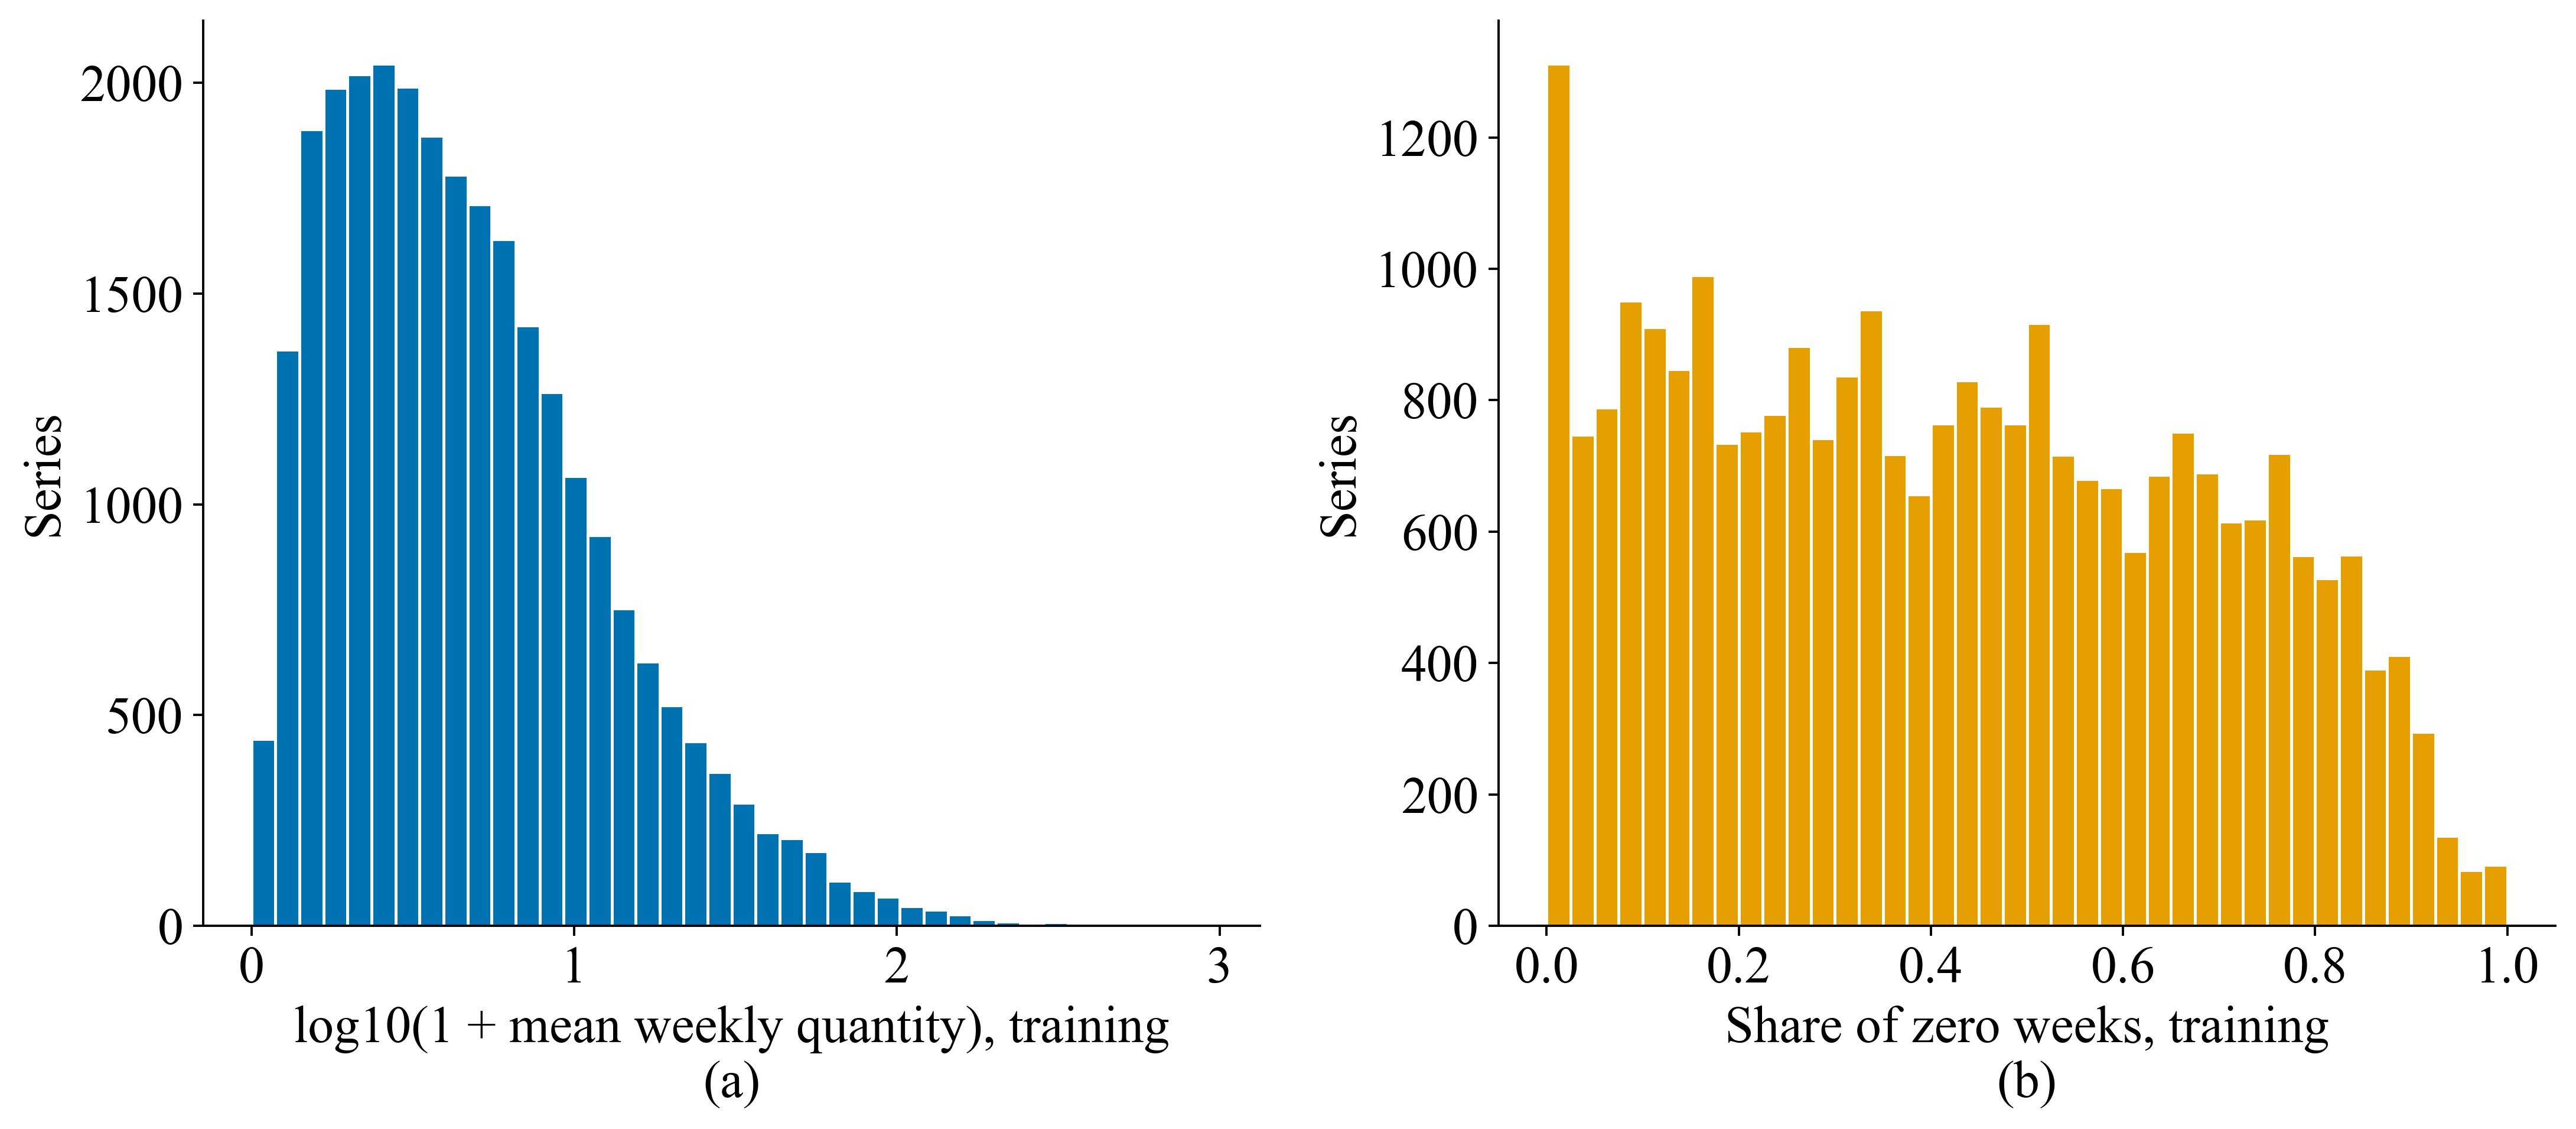

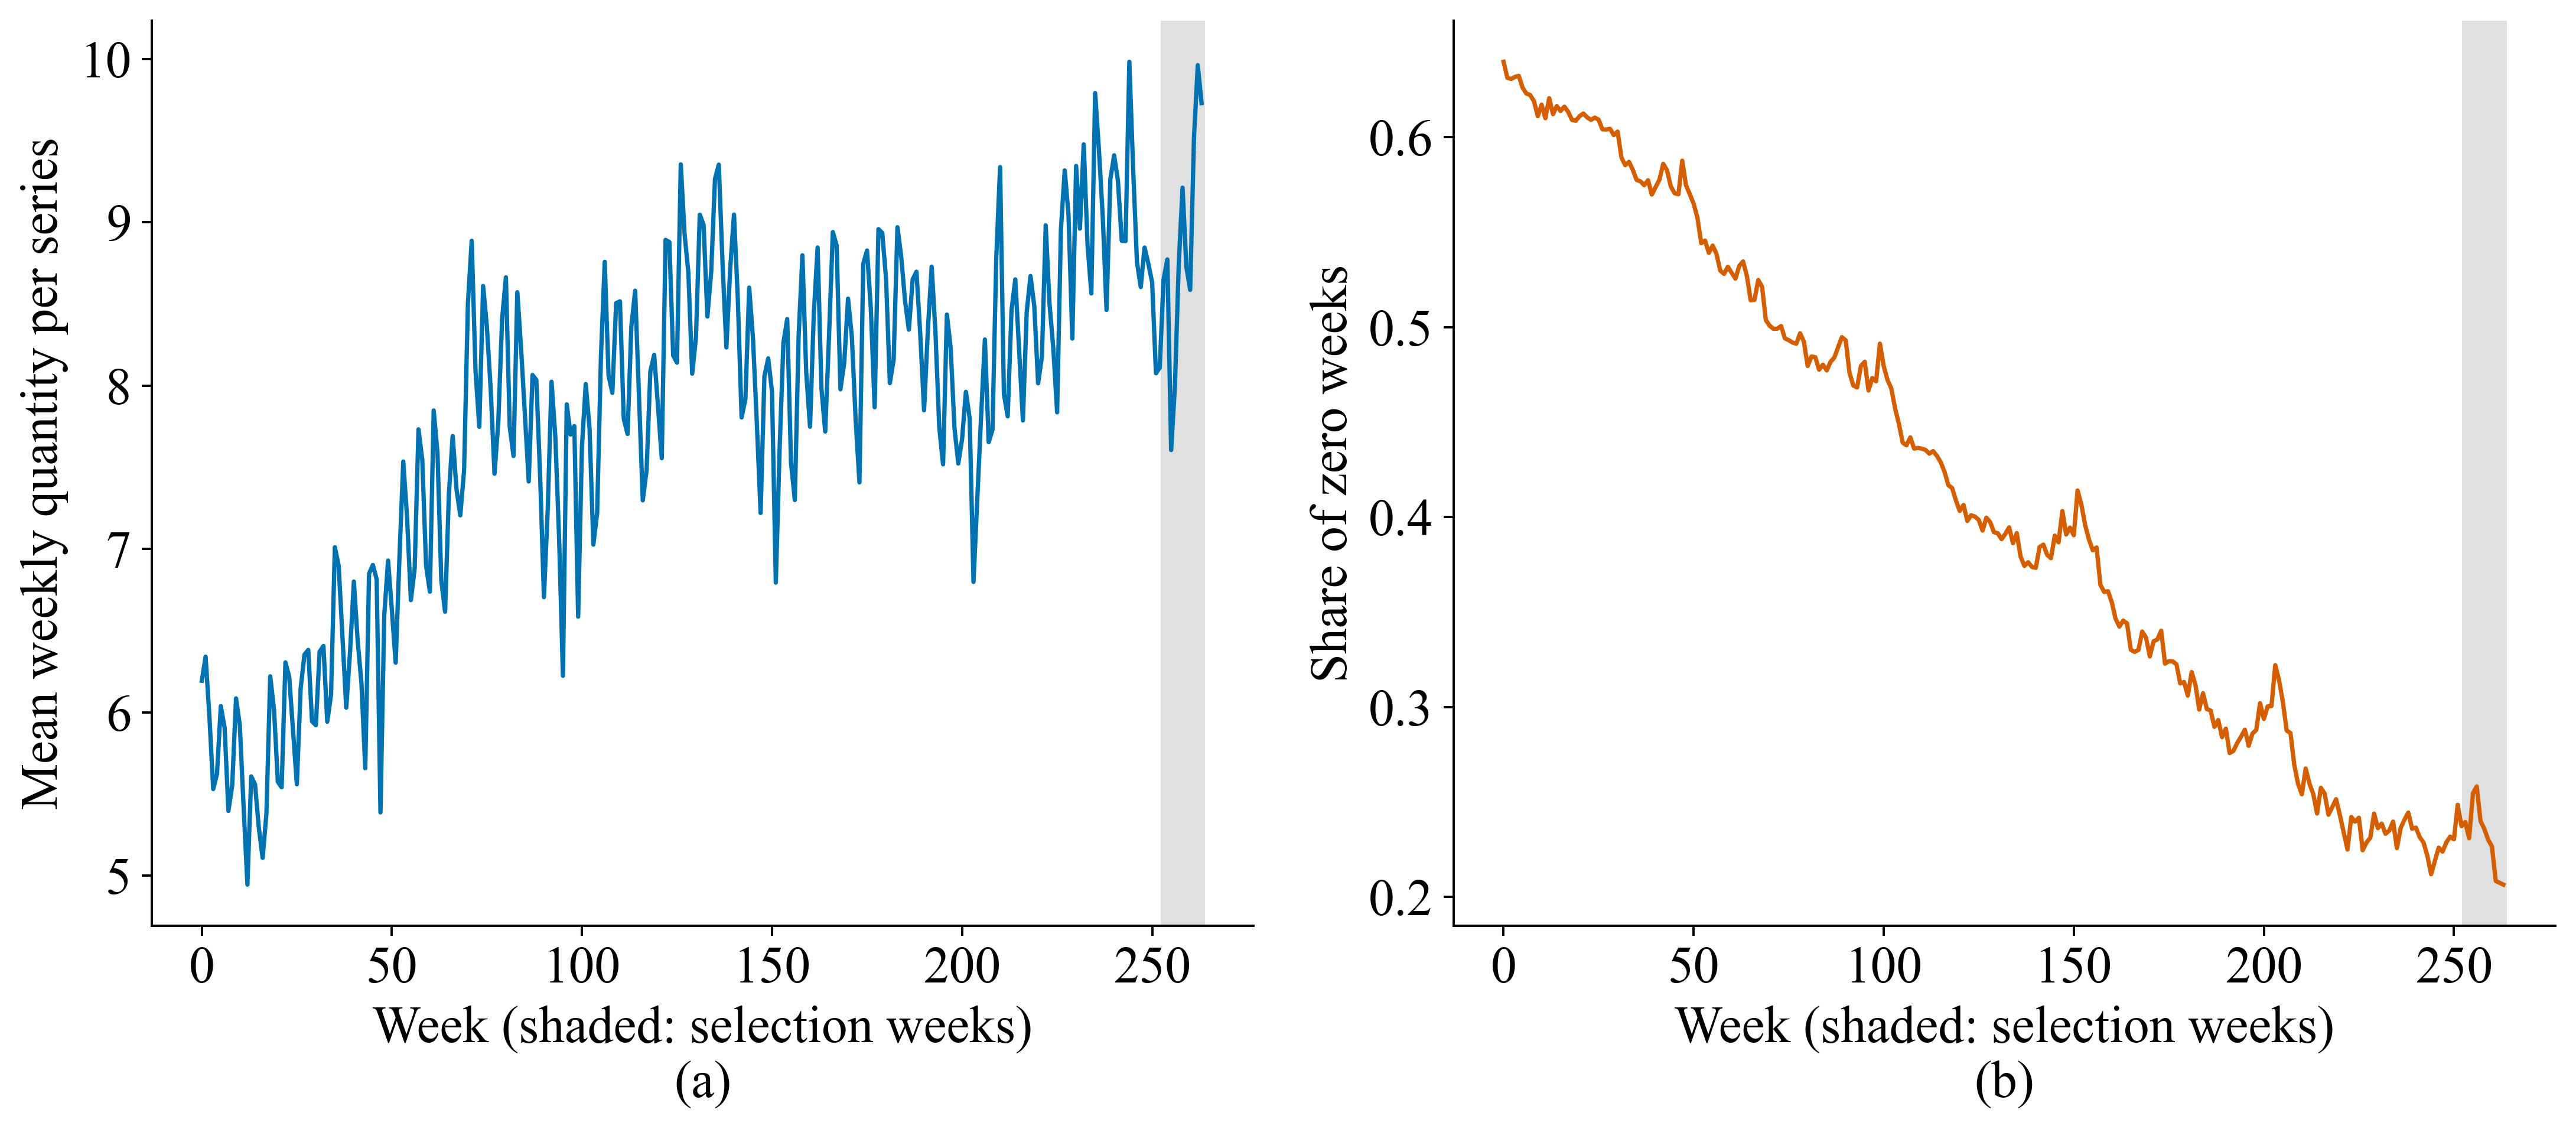

In [5]:
# NB01_FIGURES
fig,axes=plt.subplots(1,2,figsize=(12.8,5.8))
axes[0].hist(np.log10(PRODUCT['mean'].to_numpy()+1),bins=40,color=PALETTE[0],edgecolor='white');axes[0].set(xlabel='log10(1 + mean weekly quantity), training',ylabel='Series')
axes[1].hist(PRODUCT.zero_share.to_numpy(),bins=40,color=PALETTE[1],edgecolor='white');axes[1].set(xlabel='Share of zero weeks, training',ylabel='Series')
label_panels(axes);fig.tight_layout();figure(fig,'fig_m5_training_distributions')
weekly_tot=long.groupby('week').quantity.agg(['sum','mean']);zero_w=long.groupby('week').quantity.apply(lambda x:float((x==0).mean()))
fig,axes=plt.subplots(1,2,figsize=(12.8,5.8))
axes[0].plot(weekly_tot.index,weekly_tot['mean'],color=PALETTE[0]);axes[0].axvspan(252.5,263.5,color='0.88',zorder=0);axes[0].set(xlabel='Week (shaded: selection weeks)',ylabel='Mean weekly quantity per series')
axes[1].plot(zero_w.index,zero_w.to_numpy(),color=PALETTE[3]);axes[1].axvspan(252.5,263.5,color='0.88',zorder=0);axes[1].set(xlabel='Week (shaded: selection weeks)',ylabel='Share of zero weeks')
label_panels(axes);fig.tight_layout();figure(fig,'fig_m5_temporal_structure')
weekly_tot.rename_axis('week').reset_index().to_csv(OUT/'weekly_totals.csv',index=False)

### Forecast information set

In [6]:
# NB01_DESIGN: forecast information set
POLICIES=pd.DataFrame([
 {'Topic':'Unit','Decision':'Unit sales per item-store series summed over complete Walmart weeks (Saturday to Friday); 277 weeks W0–W276.'},
 {'Topic':'Forecast timing','Decision':'At the start of week t, predict the quantity of week t; the latest observed quantity is t−2 (one-week reporting delay).'},
 {'Topic':'Cohorts','Decision':f'{len(CORE)} core series for fitting and selection; {len(EXTERNAL)} external series allocated by hash before parsing, outcomes sealed.'},
 {'Topic':'Splits','Decision':'Training W0–W251 (initial fit latest label W251); selection W253–W263; gap W264 never scored; locked W265–W276.'},
 {'Topic':'Nested stages','Decision':'F0 fit ≤ W239 → W241–W243; F1 ≤ W243 → W245–W248; F2 ≤ W247 → W249–W252; learned models fit on the 104 weeks before the latest label.'},
 {'Topic':'Covariates','Decision':'Sell prices, calendar events and SNAP days are planned covariates known at the forecast date; sales-derived features use outcomes through t−2 only.'},
 {'Topic':'Zeros','Decision':'All zero weeks are retained, including structurally zero weeks before the first sale; RMSPE uses positive targets with zero support reported.'},
 {'Topic':'Sealed read','Decision':'Weeks 265–276 (core and external) are read once, in NB06.'}])
table(POLICIES,'design_policies')
dump(BASE/'Manifests/latest_runs.json',{'NB01':RUN_ID})


,Topic,Decision
0,Unit,Unit sales per item-store series summed over complete Walmart weeks (Saturday to Friday); 277 weeks W0–W276.
1,Forecast timing,"At the start of week t, predict the quantity of week t; the latest observed quantity is t−2 (one-week reporting delay)."
2,Cohorts,"27441 core series for fitting and selection; 3049 external series allocated by hash before parsing, outcomes sealed."
3,Splits,Training W0–W251 (initial fit latest label W251); selection W253–W263; gap W264 never scored; locked W265–W276.
4,Nested stages,F0 fit ≤ W239 → W241–W243; F1 ≤ W243 → W245–W248; F2 ≤ W247 → W249–W252; learned models fit on the 104 weeks before the latest label.
5,Covariates,"Sell prices, calendar events and SNAP days are planned covariates known at the forecast date; sales-derived features use outcomes through t−2 only."
6,Zeros,"All zero weeks are retained, including structurally zero weeks before the first sale; RMSPE uses positive targets with zero support reported."
7,Sealed read,"Weeks 265–276 (core and external) are read once, in NB06."
